In [8]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.titleweight"] = "bold"
pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

DATA_DIR = "data"          # put both CSV files in this folder
os.makedirs("images", exist_ok=True)   # charts are saved here (handy for the GitHub README)

def save_fig(name):
    plt.tight_layout()
    plt.savefig(f"images/{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

In [2]:
pip install seaborn

Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/294.9 kB ? eta -:--:--
   - -------------------------------------- 10.2/294.9 kB ? eta -:--:--
   - -------------------------------------- 10.2/294.9 kB ? eta -:--:--
   ---- ---------------------------------- 30.7/294.9 kB 217.9 kB/s eta 0:00:02
   ----- --------------------------------- 41.0/294.9 kB 217.9 kB/s eta 0:00:02
   -------------- ----------------------- 112.6/294.9 kB 544.7 kB/s eta 0:00:01
   ----------------------------- -------- 225.3/294.9 kB 919.0 kB/s eta 0:00:01
   ---------------------------------------- 294.9/294.9 kB 1.1 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [9]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.titleweight"] = "bold"
pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

DATA_DIR = "data"          # put both CSV files in this folder
os.makedirs("images", exist_ok=True)   # charts are saved here (handy for the GitHub README)

def save_fig(name):
    plt.tight_layout()
    plt.savefig(f"images/{name}.png", dpi=150, bbox_inches="tight")
    plt.show()


In [11]:
fact = pd.read_csv(f"{DATA_DIR}/apollo_appointments_fact.csv", keep_default_na=False, na_values=[""])
doctors = pd.read_csv(f"{DATA_DIR}/apollo_doctors_dim.csv", keep_default_na=False, na_values=[""])

print("Fact table   :", fact.shape)
print("Doctors table:", doctors.shape)
fact.head()

Fact table   : (75000, 52)
Doctors table: (320, 15)


,appointment_id,patient_id,doctor_id,appointment_date,appointment_day,appointment_day_of_week,appointment_month,appointment_quarter,appointment_year,appointment_hour,appointment_minute,time_slot,time_of_day,booking_date,booking_lead_days,booking_channel,appointment_type,specialty,city,state,hospital_name,patient_age,age_group,patient_gender,patient_city_tier,patient_chronic_condition,apollo_member,membership_type,reminder_type,reminders_sent,patient_prior_visits,patient_prior_no_shows,is_first_visit,repeat_visit,visit_reason,appointment_status,no_show,no_show_flag,cancellation_reason,consultation_fee,discount_pct,actual_fee_charged,insurance_coverage,insurance_provider,insurance_covered_amount,patient_out_of_pocket,revenue_realized,payment_mode,wait_time_minutes,consultation_duration_min,patient_satisfaction_score,doctor_utilization_pct
0,APPT5000001,PAT117608,DOC1035,2023-11-15,Wednesday,2,11,Q4,2023,15,30,15:30,Afternoon,2023-11-14,1,Apollo App,In-Clinic,Cardiology,Bengaluru,Karnataka,Apollo Clinic Jayanagar,76,Senior (60+),Female,1,None,No,None,SMS + WhatsApp,2,1,0,0,Yes,Joint Pain,Completed,No,0,None,2700,0,2700,No,None,0,2700,2700,UPI,11.00,40.00,4.80,84.20
1,APPT5000002,PAT128732,DOC1049,2023-03-13,Monday,0,3,Q1,2023,9,0,09:00,Morning,2023-03-05,8,Website,In-Clinic,Paediatrics,Pune,Maharashtra,Apollo Spectra Pune,6,Child (0-12),Male,1,None,No,None,SMS Only,1,1,0,0,Yes,Fever & Infection,Completed,No,0,None,1400,0,1400,No,None,0,1400,1400,UPI,21.00,18.00,4.10,64.50
2,APPT5000003,PAT137532,DOC1033,2022-02-07,Monday,0,2,Q1,2022,17,0,17:00,Evening,2022-02-07,0,Walk-In,In-Clinic,General Physician,Bengaluru,Karnataka,Apollo Spectra Koramangala,69,Senior (60+),Male,1,Hypothyroidism,No,None,SMS + WhatsApp + Call,3,1,0,0,Yes,Routine Checkup,Completed,No,0,None,600,0,600,No,None,0,600,600,Net Banking,6.00,6.00,5.00,75.60
3,APPT5000004,PAT113284,DOC1288,2023-11-20,Monday,0,11,Q4,2023,17,15,17:15,Evening,2023-11-20,0,Walk-In,In-Clinic,Dermatology,Delhi,Delhi,Apollo Hospital Sarita Vihar,47,Middle-aged (46-60),Female,1,Hypertension,No,None,SMS + WhatsApp + Call,3,1,0,0,Yes,Eye Care,Completed,No,0,None,1275,0,1275,No,None,0,1275,1275,UPI,2.00,25.00,4.40,68.60
4,APPT5000005,PAT107443,DOC1064,2024-02-02,Friday,4,2,Q1,2024,19,30,19:30,Evening,2024-02-01,1,Apollo App,In-Clinic,Gastroenterology,Coimbatore,Tamil Nadu,Apollo Clinic Coimbatore,45,Adult (31-45),Female,2,Hypertension,Yes,Apollo Silver,SMS + WhatsApp,2,1,0,0,Yes,Respiratory Issue,Completed,No,0,None,2000,15,1700,No,None,0,1700,1700,Cash,7.00,13.00,3.50,67.70


In [12]:
doctors.head()

,doctor_id,doctor_name,specialty,qualification,experience_years,city,state,hospital_name,consultation_fee,rating,total_reviews,available_days,avg_slot_duration_min,accepts_insurance,teleconsult_enabled
0,DOC1001,Dr. Deepa Sharma,Urology,"MBBS, MCh",12,Bengaluru,Karnataka,Apollo Hospital Bannerghatta,2300,4.40,1502,Mon-Fri,15,Yes,No
1,DOC1002,Dr. Venkatesan Khan,Paediatrics,"MBBS, MS, FRCS",25,Chandigarh,Punjab,Apollo Clinic Sector 8,1200,4.50,2453,Mon-Sat,10,Yes,Yes
2,DOC1003,Dr. Pradeep Menon,General Physician,"MBBS, DM",13,Mumbai,Maharashtra,Apollo Clinic Andheri,700,4.70,995,Mon-Wed-Fri-Sat,15,No,No
3,DOC1004,Dr. Vivek Mathew,General Physician,"MBBS, MD",31,Mumbai,Maharashtra,Apollo Hospital Navi Mumbai,1000,4.90,666,Mon-Wed-Fri-Sat,20,Yes,Yes
4,DOC1005,Dr. Savita Philip,General Physician,"MBBS, MD, PhD",5,Mumbai,Maharashtra,Apollo Hospital Navi Mumbai,600,4.50,1383,Mon-Sat,30,Yes,Yes


In [13]:
fact.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 75000 entries, 0 to 74999
Data columns (total 52 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   appointment_id              75000 non-null  object 
 1   patient_id                  75000 non-null  object 
 2   doctor_id                   75000 non-null  object 
 3   appointment_date            75000 non-null  object 
 4   appointment_day             75000 non-null  object 
 5   appointment_day_of_week     75000 non-null  int64  
 6   appointment_month           75000 non-null  int64  
 7   appointment_quarter         75000 non-null  object 
 8   appointment_year            75000 non-null  int64  
 9   appointment_hour            75000 non-null  int64  
 10  appointment_minute          75000 non-null  int64  
 11  time_slot                   75000 non-null  object 
 12  time_of_day                 75000 non-null  object 
 13  booking_date                750

In [14]:
missing = fact.isna().sum()
print(missing[missing > 0])

print("\nDuplicate appointment_id :", fact["appointment_id"].duplicated().sum())
print("Fully duplicated rows     :", fact.duplicated().sum())
print("Doctor IDs in fact not in dim:", (~fact["doctor_id"].isin(doctors["doctor_id"])).sum())

wait_time_minutes             19725
consultation_duration_min     19725
patient_satisfaction_score    19725
doctor_utilization_pct        19725
dtype: int64

Duplicate appointment_id : 0
Fully duplicated rows     : 0
Doctor IDs in fact not in dim: 0


In [15]:
quality_cols = ["wait_time_minutes", "consultation_duration_min", "patient_satisfaction_score", "doctor_utilization_pct"]
print(fact.groupby("appointment_status")[quality_cols].count())

print("\nRevenue by status (should be 0 for non-Completed):")
print(fact.groupby("appointment_status")["revenue_realized"].sum())

                    wait_time_minutes  consultation_duration_min  \
appointment_status                                                 
Cancelled                           0                          0   
Completed                       55275                      55275   
No-Show                             0                          0   
Scheduled                           0                          0   

                    patient_satisfaction_score  doctor_utilization_pct  
appointment_status                                                      
Cancelled                                    0                       0  
Completed                                55275                   55275  
No-Show                                      0                       0  
Scheduled                                    0                       0  

Revenue by status (should be 0 for non-Completed):
appointment_status
Cancelled           0
Completed    73893798
No-Show             0
Scheduled       

In [16]:
fact.describe().T

,count,mean,std,min,25%,50%,75%,max
appointment_day_of_week,"75,000.00",3.01,2.00,0.00,1.00,3.00,5.00,6.00
appointment_month,"75,000.00",6.55,3.57,1.00,3.00,7.00,10.00,12.00
appointment_year,"75,000.00","2,023.00",0.82,"2,022.00","2,022.00","2,023.00","2,024.00","2,024.00"
appointment_hour,"75,000.00",12.76,3.43,8.00,10.00,12.00,16.00,19.00
appointment_minute,"75,000.00",22.59,16.78,0.00,15.00,30.00,45.00,45.00
booking_lead_days,"75,000.00",3.62,4.39,0.00,0.00,2.00,5.00,30.00
patient_age,"75,000.00",38.75,22.63,1.00,19.00,39.00,57.00,85.00
patient_city_tier,"75,000.00",1.29,0.45,1.00,1.00,1.00,2.00,2.00
reminders_sent,"75,000.00",1.80,1.03,0.00,1.00,2.00,3.00,3.00
patient_prior_visits,"75,000.00",1.47,1.06,0.00,1.00,1.00,2.00,9.00


In [18]:
fact["appointment_date"] = pd.to_datetime(fact["appointment_date"])
fact["booking_date"] = pd.to_datetime(fact["booking_date"])

fact["year_month"] = fact["appointment_date"].dt.to_period("M").astype(str)
fact["year_quarter"] = fact["appointment_year"].astype(str) + "-" + fact["appointment_quarter"]
fact["is_weekend"] = np.where(fact["appointment_day_of_week"] >= 5, "Weekend", "Weekday")

fact["lead_bucket"] = pd.cut(
    fact["booking_lead_days"],
    bins=[-1, 0, 3, 7, 14, 30],
    labels=["Same day (0)", "1-3 days", "4-7 days", "8-14 days", "15-30 days"],
)

day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
age_order = ["Child (0-12)", "Teen (13-18)", "Young Adult (19-30)", "Adult (31-45)", "Middle-aged (46-60)", "Senior (60+)"]

completed = fact[fact["appointment_status"] == "Completed"].copy()
resolved = fact[fact["appointment_status"].isin(["Completed", "No-Show", "Cancelled"])].copy()

# Join with doctors dimension (only bring doctor-level attributes to avoid duplicate column names)
doc_cols = ["doctor_id", "doctor_name", "qualification", "experience_years", "rating",
            "total_reviews", "avg_slot_duration_min", "accepts_insurance", "teleconsult_enabled"]
fact_doc = fact.merge(doctors[doc_cols], on="doctor_id", how="left")
completed_doc = fact_doc[fact_doc["appointment_status"] == "Completed"].copy()

print(f"All: {len(fact):,} | Resolved (for no-show rate): {len(resolved):,} | Completed: {len(completed):,}")

All: 75,000 | Resolved (for no-show rate): 72,652 | Completed: 55,275


In [19]:
def noshow_rate(df, by):
    """No-show rate (%) = No-Show / (Completed + No-Show + Cancelled). Scheduled rows are excluded."""
    out = (df.groupby(by, observed=True)
             .agg(appointments=("appointment_id", "count"),
                  no_shows=("no_show_flag", "sum")))
    out["no_show_rate_%"] = out["no_shows"] / out["appointments"] * 100
    return out

overall_ns = resolved["no_show_flag"].mean() * 100
print(f"Overall no-show rate: {overall_ns:.2f}%")

Overall no-show rate: 15.94%


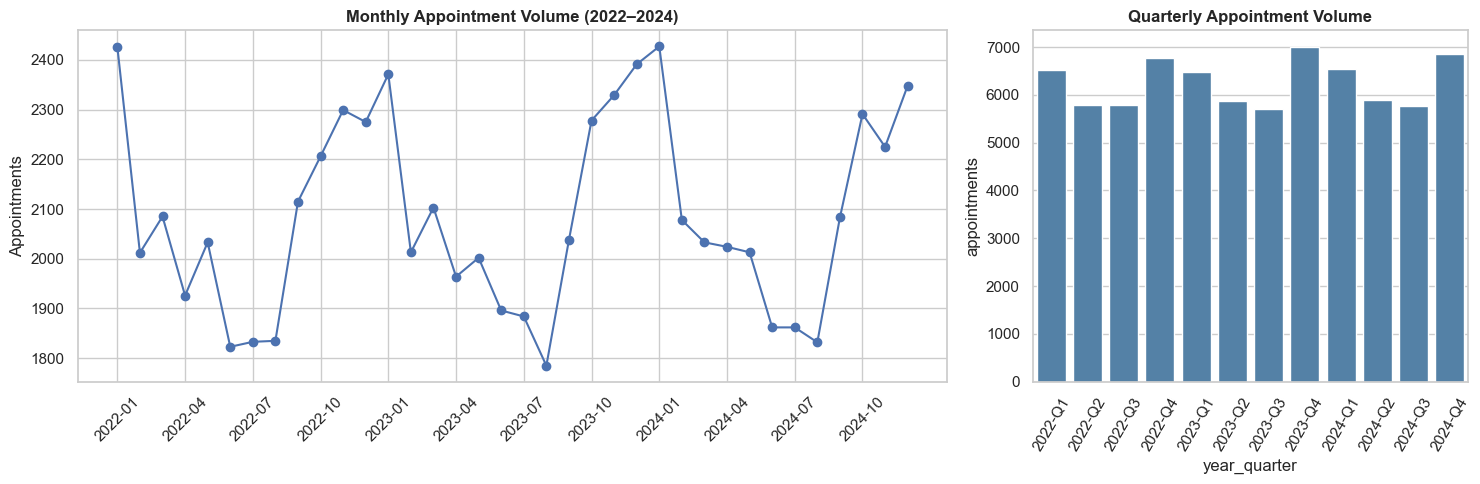

Appointments per year:
 appointment_year
2022    24868
2023    25054
2024    25078
dtype: int64

YoY growth %:
 appointment_year
2022    NaN
2023   0.70
2024   0.10
dtype: float64


In [20]:
monthly = fact.groupby("year_month").size().reset_index(name="appointments")
quarterly = fact.groupby("year_quarter").size().reset_index(name="appointments")

fig, ax = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={"width_ratios": [2, 1]})
ax[0].plot(monthly["year_month"], monthly["appointments"], marker="o")
ax[0].set_title("Monthly Appointment Volume (2022–2024)")
ax[0].set_xticks(range(0, len(monthly), 3))
ax[0].set_xticklabels(monthly["year_month"][::3], rotation=45)
ax[0].set_ylabel("Appointments")

sns.barplot(data=quarterly, x="year_quarter", y="appointments", ax=ax[1], color="steelblue")
ax[1].set_title("Quarterly Appointment Volume")
ax[1].tick_params(axis="x", rotation=60)
save_fig("01_volume_trend")

yearly = fact.groupby("appointment_year").size()
print("Appointments per year:\n", yearly)
print("\nYoY growth %:\n", yearly.pct_change().mul(100).round(1))

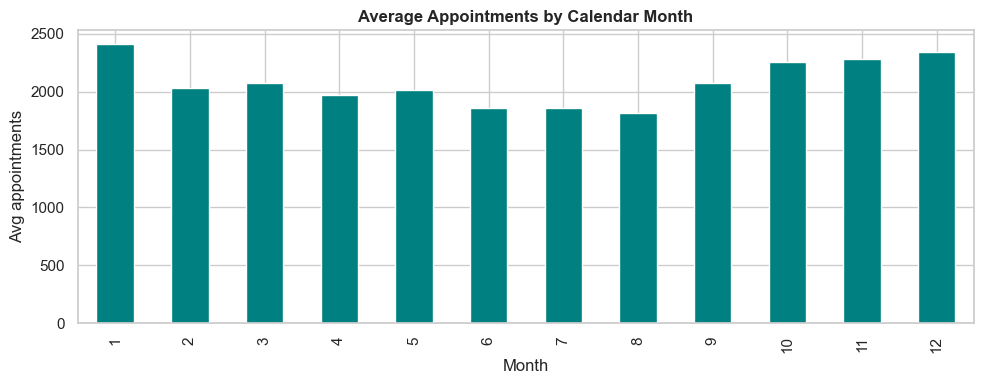

In [21]:
# Seasonality: average appointments per calendar month across the 3 years
season = fact.groupby(["appointment_year", "appointment_month"]).size().unstack(0)
season["avg"] = season.mean(axis=1)
season["avg"].plot(kind="bar", color="teal", figsize=(10, 4), title="Average Appointments by Calendar Month")
plt.xlabel("Month"); plt.ylabel("Avg appointments")
save_fig("01b_seasonality")

,count,share_%
appointment_status,,
Completed,55275,73.70
No-Show,11584,15.45
Cancelled,5793,7.72
Scheduled,2348,3.13


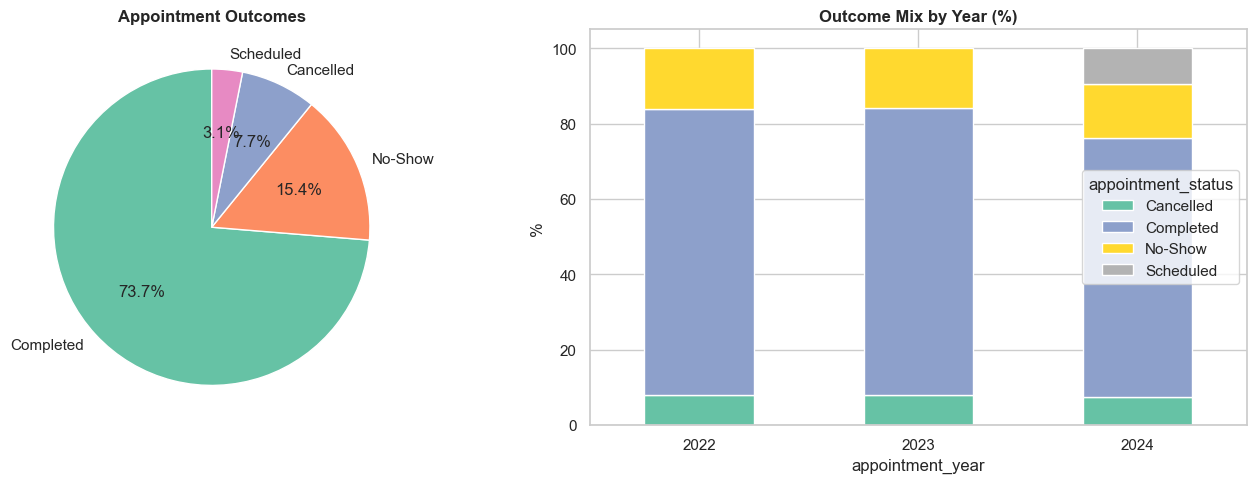

In [22]:
status = fact["appointment_status"].value_counts()
status_pct = fact["appointment_status"].value_counts(normalize=True).mul(100)
display(pd.DataFrame({"count": status, "share_%": status_pct}))

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].pie(status, labels=status.index, autopct="%1.1f%%", startangle=90,
          colors=sns.color_palette("Set2"), wedgeprops={"edgecolor": "white"})
ax[0].set_title("Appointment Outcomes")

by_year = pd.crosstab(fact["appointment_year"], fact["appointment_status"], normalize="index") * 100
by_year.plot(kind="bar", stacked=True, ax=ax[1], colormap="Set2")
ax[1].set_title("Outcome Mix by Year (%)"); ax[1].set_ylabel("%"); ax[1].tick_params(axis="x", rotation=0)
save_fig("02_outcome_split")

,count,share_%
booking_channel,,
Apollo App,34042,45.39
Website,18545,24.73
Call Centre,11201,14.93
Walk-In,7501,10.00
Partner App,3711,4.95


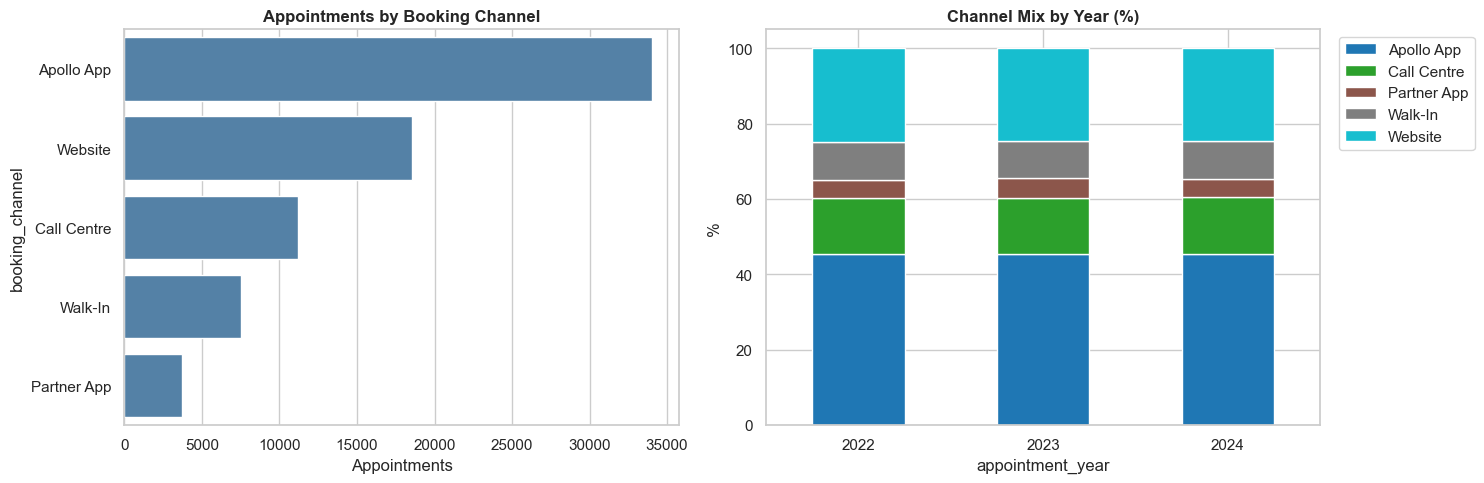

In [23]:
channel = fact["booking_channel"].value_counts()
display(pd.DataFrame({"count": channel, "share_%": channel / channel.sum() * 100}))

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
sns.barplot(x=channel.values, y=channel.index, ax=ax[0], color="steelblue")
ax[0].set_title("Appointments by Booking Channel"); ax[0].set_xlabel("Appointments")

ch_year = pd.crosstab(fact["appointment_year"], fact["booking_channel"], normalize="index") * 100
ch_year.plot(kind="bar", stacked=True, ax=ax[1], colormap="tab10")
ax[1].set_title("Channel Mix by Year (%)"); ax[1].set_ylabel("%"); ax[1].tick_params(axis="x", rotation=0)
ax[1].legend(bbox_to_anchor=(1.02, 1), loc="upper left")
save_fig("03_channel_mix")

In [25]:
##> No-show rate = No-Show ÷ (Completed + No-Show + Cancelled). *Scheduled* rows are excluded.


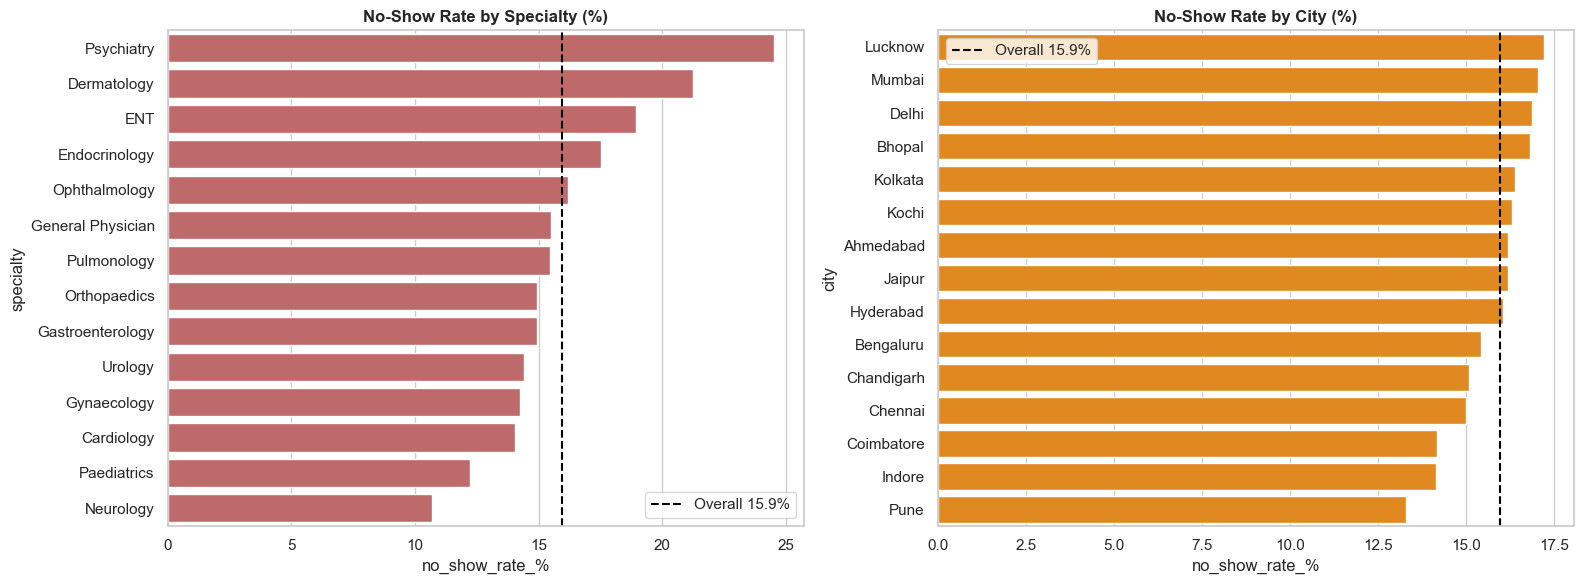

Specialty - highest: Psychiatry (24.5%) | lowest: Neurology (10.7%)
City      - highest: Lucknow (17.2%) | lowest: Pune (13.3%)


,appointments,no_shows,no_show_rate_%
specialty,,,
Psychiatry,2900,711,24.52
Dermatology,7566,1608,21.25
ENT,5211,988,18.96
Endocrinology,2024,355,17.54
Ophthalmology,3103,503,16.21
General Physician,19654,3049,15.51
Pulmonology,2549,394,15.46
Orthopaedics,5419,810,14.95
Gastroenterology,2527,377,14.92


,appointments,no_shows,no_show_rate_%
city,,,
Lucknow,3001,516,17.19
Mumbai,9734,1659,17.04
Delhi,10404,1754,16.86
Bhopal,2001,336,16.79
Kolkata,5701,933,16.37
Kochi,2690,438,16.28
Ahmedabad,3468,561,16.18
Jaipur,2653,429,16.17
Hyderabad,7229,1160,16.05


In [26]:
spec_ns = noshow_rate(resolved, "specialty").sort_values("no_show_rate_%", ascending=False)
city_ns = noshow_rate(resolved, "city").sort_values("no_show_rate_%", ascending=False)

fig, ax = plt.subplots(1, 2, figsize=(16, 6))
sns.barplot(x=spec_ns["no_show_rate_%"], y=spec_ns.index, ax=ax[0], color="indianred")
ax[0].axvline(overall_ns, color="black", ls="--", label=f"Overall {overall_ns:.1f}%"); ax[0].legend()
ax[0].set_title("No-Show Rate by Specialty (%)")
sns.barplot(x=city_ns["no_show_rate_%"], y=city_ns.index, ax=ax[1], color="darkorange")
ax[1].axvline(overall_ns, color="black", ls="--", label=f"Overall {overall_ns:.1f}%"); ax[1].legend()
ax[1].set_title("No-Show Rate by City (%)")
save_fig("04_noshow_specialty_city")

print("Specialty - highest:", spec_ns.index[0], f"({spec_ns['no_show_rate_%'].iloc[0]:.1f}%) | lowest:", spec_ns.index[-1], f"({spec_ns['no_show_rate_%'].iloc[-1]:.1f}%)")
print("City      - highest:", city_ns.index[0], f"({city_ns['no_show_rate_%'].iloc[0]:.1f}%) | lowest:", city_ns.index[-1], f"({city_ns['no_show_rate_%'].iloc[-1]:.1f}%)")
display(spec_ns); display(city_ns)

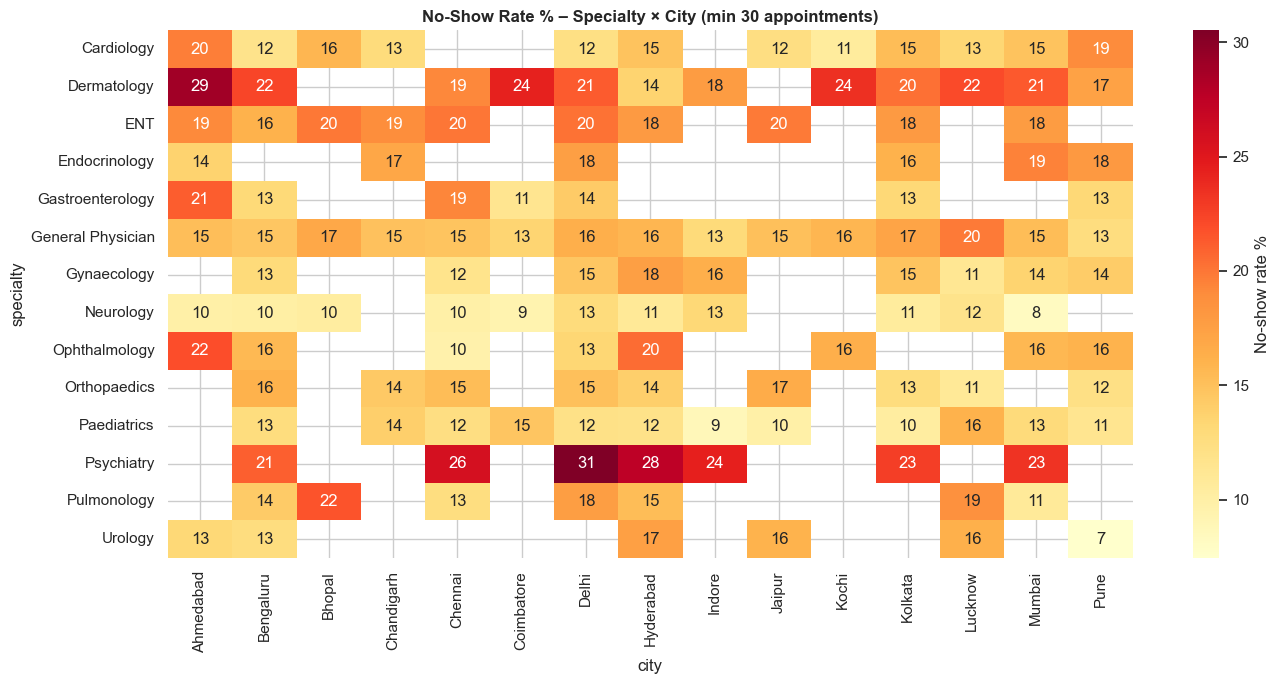

In [27]:
# Heatmap: specialty x city (cells with small samples are masked)
pivot = resolved.pivot_table(index="specialty", columns="city", values="no_show_flag", aggfunc="mean") * 100
counts = resolved.pivot_table(index="specialty", columns="city", values="no_show_flag", aggfunc="count")
pivot = pivot.where(counts >= 30)
plt.figure(figsize=(14, 7))
sns.heatmap(pivot, annot=True, fmt=".0f", cmap="YlOrRd", cbar_kws={"label": "No-show rate %"})
plt.title("No-Show Rate % – Specialty × City (min 30 appointments)")
save_fig("04b_heatmap_specialty_city")

,appointments,no_shows,no_show_rate_%
lead_bucket,,,
Same day (0),20180,3193,15.82
1-3 days,25475,3651,14.33
4-7 days,15897,2623,16.50
8-14 days,8758,1648,18.82
15-30 days,2342,469,20.03


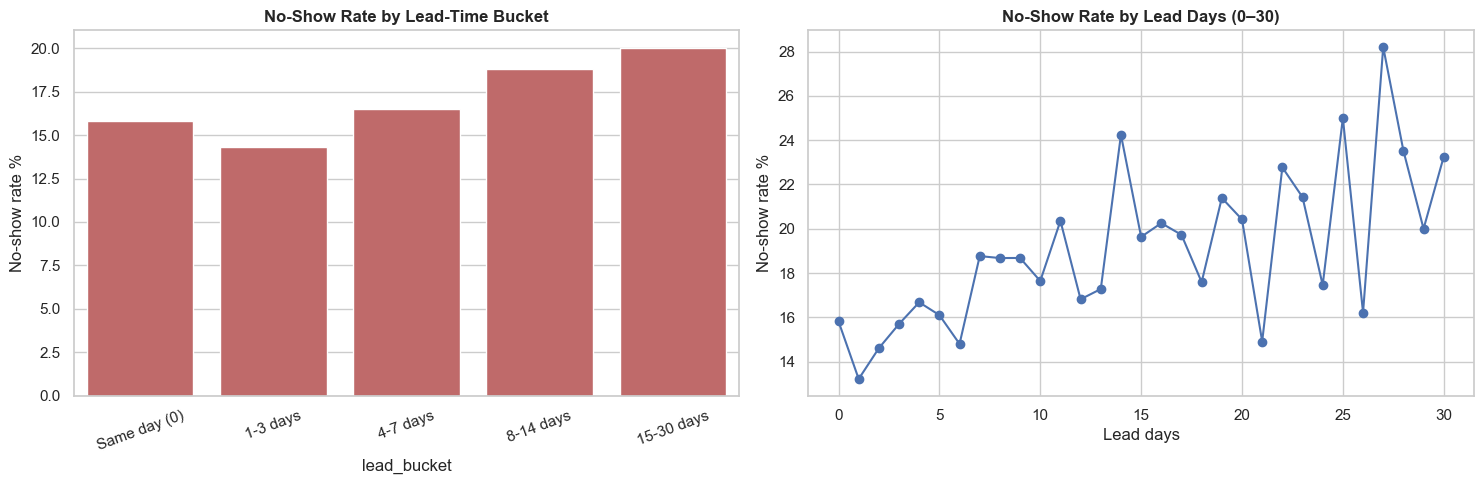

Correlation (lead days vs no-show flag): 0.038


In [28]:
lead_ns = noshow_rate(resolved, "lead_bucket")
display(lead_ns)

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
sns.barplot(x=lead_ns.index.astype(str), y=lead_ns["no_show_rate_%"], ax=ax[0], color="indianred")
ax[0].set_title("No-Show Rate by Lead-Time Bucket"); ax[0].set_ylabel("No-show rate %"); ax[0].tick_params(axis="x", rotation=20)

daily_lead = resolved.groupby("booking_lead_days")["no_show_flag"].mean() * 100
ax[1].plot(daily_lead.index, daily_lead.values, marker="o")
ax[1].set_title("No-Show Rate by Lead Days (0–30)"); ax[1].set_xlabel("Lead days"); ax[1].set_ylabel("No-show rate %")
save_fig("05_lead_time_noshow")

print("Correlation (lead days vs no-show flag):", round(resolved["booking_lead_days"].corr(resolved["no_show_flag"]), 3))

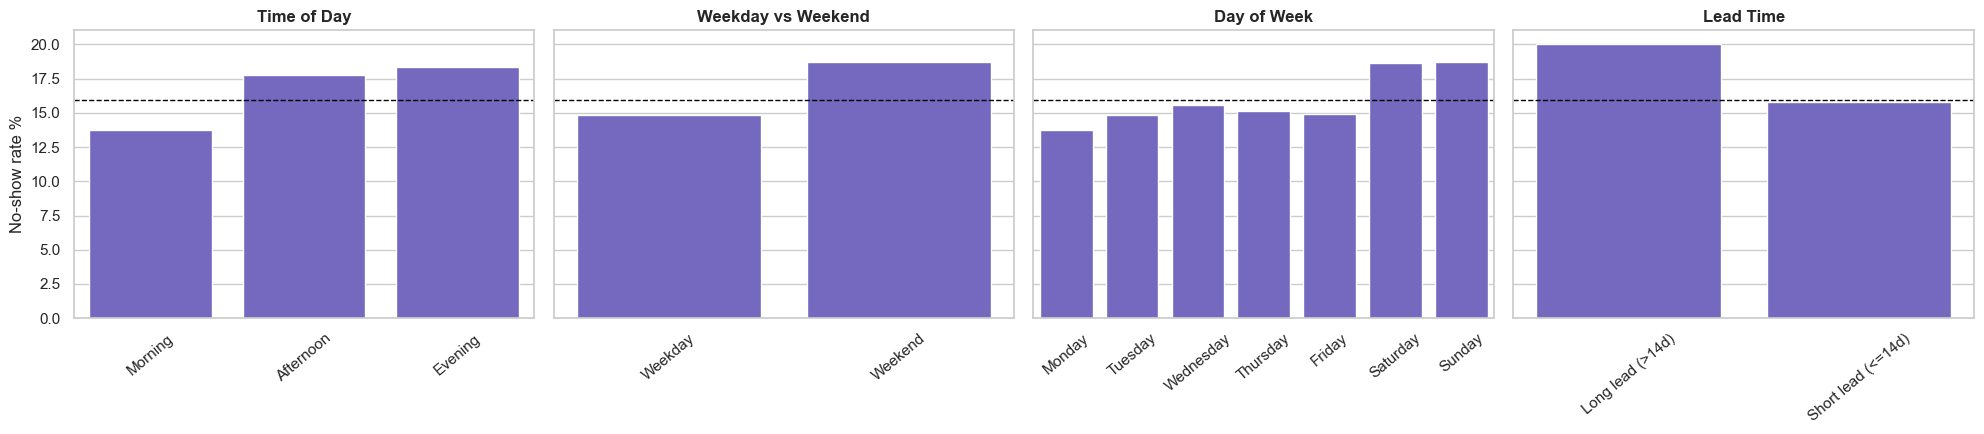

,appointments,no_shows,no_show_rate_%
time_of_day,,,
Morning,34868,4787,13.73
Afternoon,23231,4124,17.75
Evening,14553,2673,18.37


,appointments,no_shows,no_show_rate_%
is_weekend,,,
Weekday,51731,7676,14.84
Weekend,20921,3908,18.68


,appointments,no_shows,no_show_rate_%
long_lead,,,
Long lead (>14d),2342,469,20.03
Short lead (<=14d),70310,11115,15.81


In [29]:
tod_ns = noshow_rate(resolved, "time_of_day").reindex(["Morning", "Afternoon", "Evening"])
wk_ns = noshow_rate(resolved, "is_weekend")
dow_ns = noshow_rate(resolved, "appointment_day").reindex(day_order)
resolved["long_lead"] = np.where(resolved["booking_lead_days"] > 14, "Long lead (>14d)", "Short lead (<=14d)")
ll_ns = noshow_rate(resolved, "long_lead")

fig, ax = plt.subplots(1, 4, figsize=(20, 4.5), sharey=True)
for a, d, t in zip(ax, [tod_ns, wk_ns, dow_ns, ll_ns], ["Time of Day", "Weekday vs Weekend", "Day of Week", "Lead Time"]):
    sns.barplot(x=d.index.astype(str), y=d["no_show_rate_%"], ax=a, color="slateblue")
    a.set_title(t); a.set_xlabel(""); a.tick_params(axis="x", rotation=40)
    a.axhline(overall_ns, color="black", ls="--", lw=1)
ax[0].set_ylabel("No-show rate %")
save_fig("06_evening_weekend_lead")

display(tod_ns); display(wk_ns); display(ll_ns)

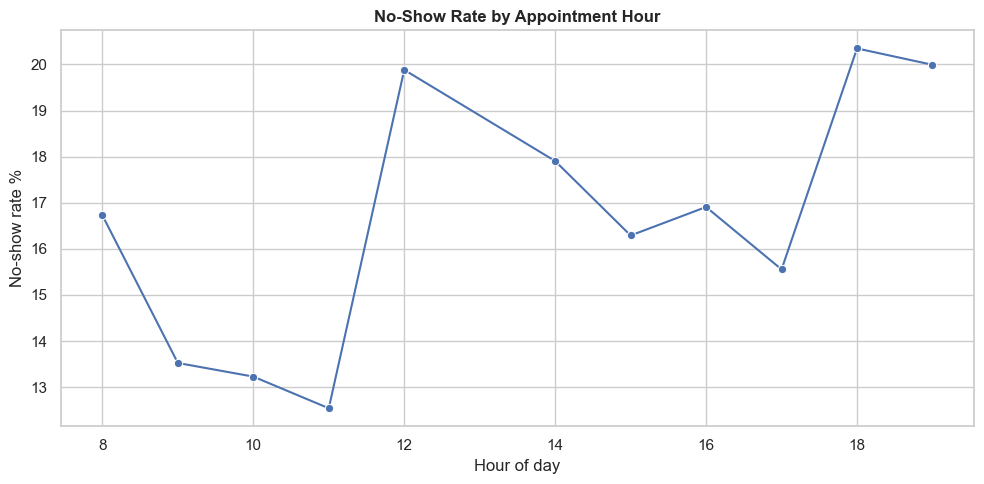

In [30]:
# Hour-by-hour view
hour_ns = noshow_rate(resolved, "appointment_hour")
sns.lineplot(x=hour_ns.index, y=hour_ns["no_show_rate_%"], marker="o")
plt.title("No-Show Rate by Appointment Hour"); plt.xlabel("Hour of day"); plt.ylabel("No-show rate %")
save_fig("06b_hourly_noshow")

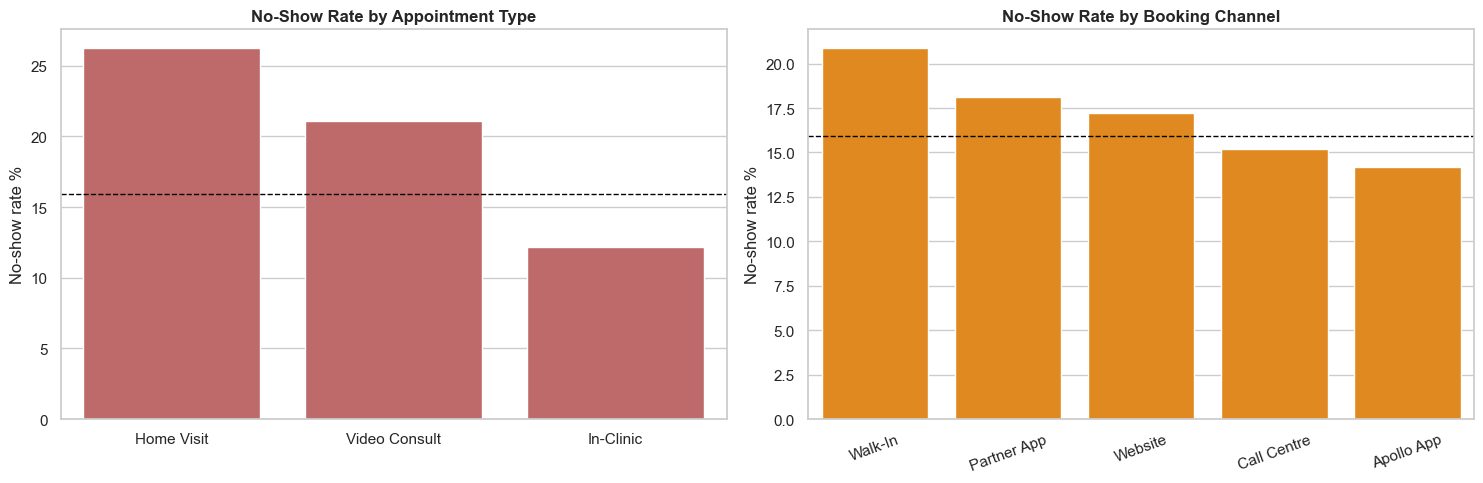

,appointments,no_shows,no_show_rate_%
appointment_type,,,
Home Visit,9742,2557,26.25
Video Consult,15349,3232,21.06
In-Clinic,47561,5795,12.18


,appointments,no_shows,no_show_rate_%
booking_channel,,,
Walk-In,7281,1520,20.88
Partner App,3594,651,18.11
Website,17964,3090,17.20
Call Centre,10855,1650,15.20
Apollo App,32958,4673,14.18


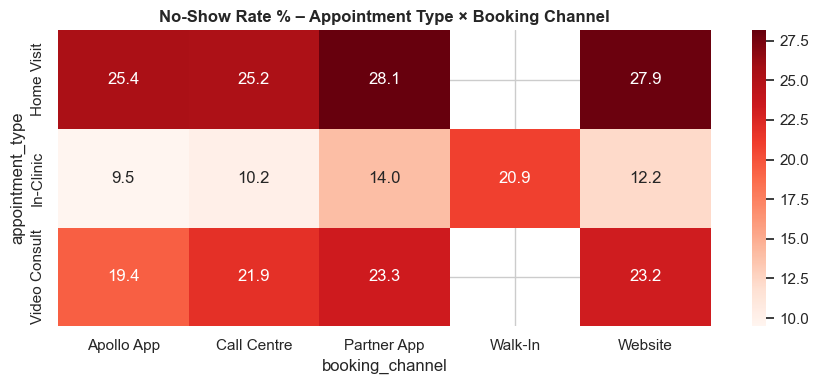

In [31]:
type_ns = noshow_rate(resolved, "appointment_type").sort_values("no_show_rate_%", ascending=False)
chan_ns = noshow_rate(resolved, "booking_channel").sort_values("no_show_rate_%", ascending=False)

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
sns.barplot(x=type_ns.index, y=type_ns["no_show_rate_%"], ax=ax[0], color="indianred")
ax[0].set_title("No-Show Rate by Appointment Type")
sns.barplot(x=chan_ns.index, y=chan_ns["no_show_rate_%"], ax=ax[1], color="darkorange")
ax[1].set_title("No-Show Rate by Booking Channel"); ax[1].tick_params(axis="x", rotation=20)
for a in ax: a.axhline(overall_ns, color="black", ls="--", lw=1); a.set_ylabel("No-show rate %"); a.set_xlabel("")
save_fig("07_noshow_type_channel")
display(type_ns); display(chan_ns)

# Type x Channel risk matrix
risk = resolved.pivot_table(index="appointment_type", columns="booking_channel", values="no_show_flag", aggfunc="mean") * 100
plt.figure(figsize=(9, 4)); sns.heatmap(risk, annot=True, fmt=".1f", cmap="Reds")
plt.title("No-Show Rate % – Appointment Type × Booking Channel")
save_fig("07b_type_channel_matrix")

,appointments,no_shows,no_show_rate_%,reduction_vs_no_reminder_pp,relative_reduction_%
reminder_type,,,,,
No Reminder,10977,3311,30.16,0.00,0.00
SMS Only,14527,2363,16.27,13.90,46.07
SMS + WhatsApp,25273,3414,13.51,16.65,55.22
SMS + WhatsApp + Call,21875,2496,11.41,18.75,62.17


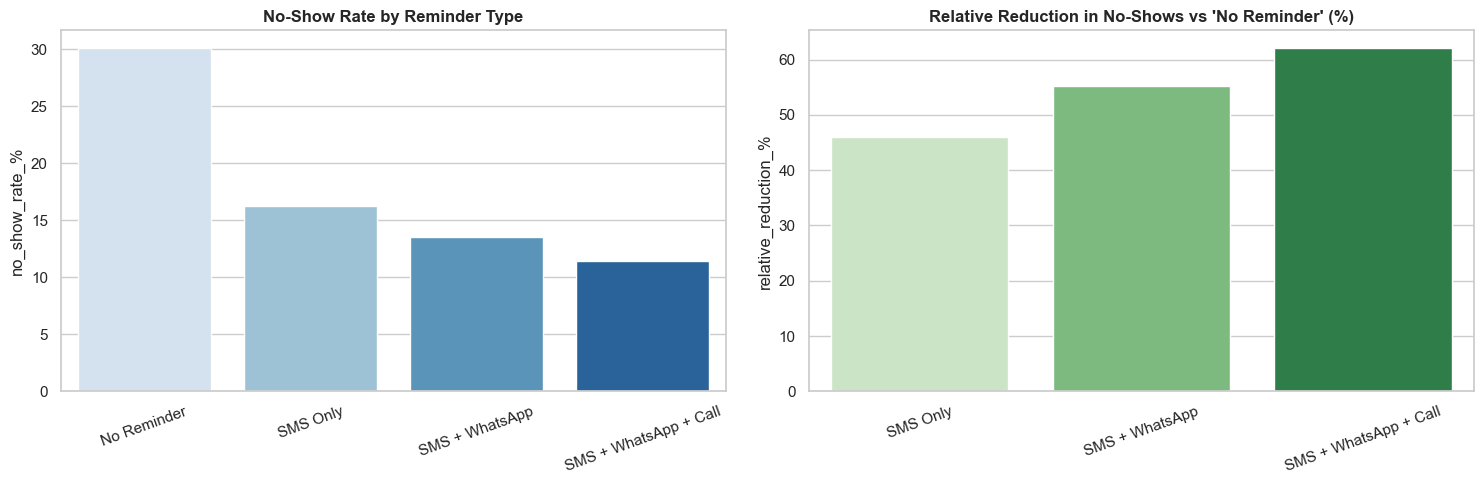

In [32]:
rem_order = ["No Reminder", "SMS Only", "SMS + WhatsApp", "SMS + WhatsApp + Call"]
rem_ns = noshow_rate(resolved, "reminder_type").reindex(rem_order)
base = rem_ns.loc["No Reminder", "no_show_rate_%"]
rem_ns["reduction_vs_no_reminder_pp"] = base - rem_ns["no_show_rate_%"]
rem_ns["relative_reduction_%"] = rem_ns["reduction_vs_no_reminder_pp"] / base * 100
display(rem_ns)

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
sns.barplot(x=rem_ns.index, y=rem_ns["no_show_rate_%"], ax=ax[0], palette="Blues")
ax[0].set_title("No-Show Rate by Reminder Type"); ax[0].tick_params(axis="x", rotation=20); ax[0].set_xlabel("")
sns.barplot(x=rem_ns.index[1:], y=rem_ns["relative_reduction_%"].iloc[1:], ax=ax[1], palette="Greens")
ax[1].set_title("Relative Reduction in No-Shows vs 'No Reminder' (%)"); ax[1].tick_params(axis="x", rotation=20); ax[1].set_xlabel("")
save_fig("08_reminder_effect")

,appointments,no_shows,no_show_rate_%
prior_ns_bucket,,,
0,63014,9549,15.15
1,8502,1723,20.27
2,983,262,26.65
3+,153,50,32.68


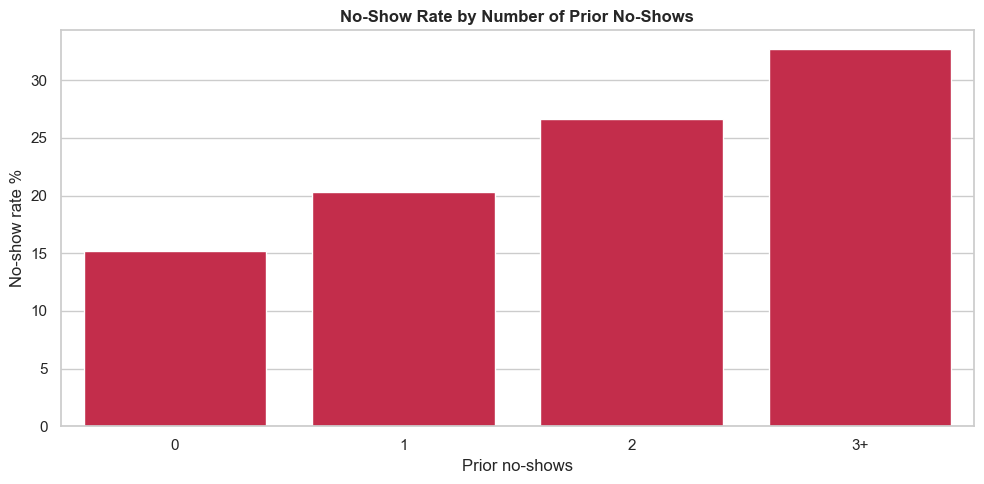

Correlation (prior no-shows vs no-show flag): 0.06


In [33]:
resolved["prior_ns_bucket"] = pd.cut(resolved["patient_prior_no_shows"], bins=[-1, 0, 1, 2, 100], labels=["0", "1", "2", "3+"])
prior_ns = noshow_rate(resolved, "prior_ns_bucket")
display(prior_ns)

sns.barplot(x=prior_ns.index.astype(str), y=prior_ns["no_show_rate_%"], color="crimson")
plt.title("No-Show Rate by Number of Prior No-Shows"); plt.xlabel("Prior no-shows"); plt.ylabel("No-show rate %")
save_fig("09_prior_noshow")

print("Correlation (prior no-shows vs no-show flag):", round(resolved["patient_prior_no_shows"].corr(resolved["no_show_flag"]), 3))

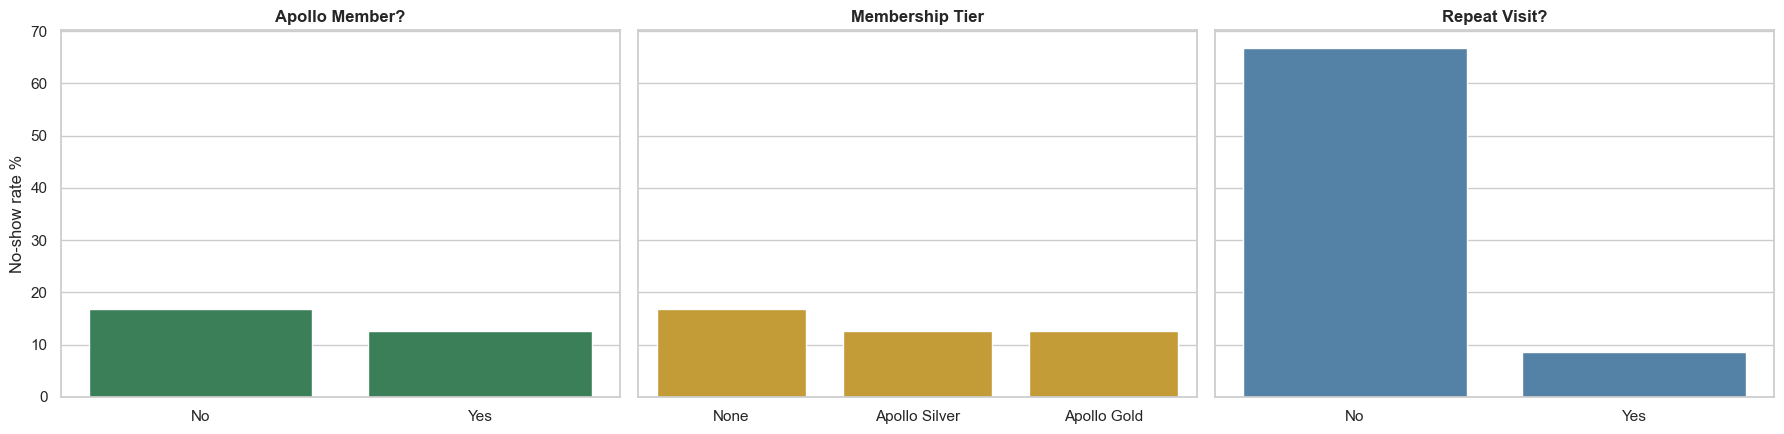

,appointments,no_shows,no_show_rate_%
apollo_member,,,
No,56428,9530,16.89
Yes,16224,2054,12.66


,appointments,no_shows,no_show_rate_%
membership_type,,,
None,56428,9530,16.89
Apollo Silver,8057,1021,12.67
Apollo Gold,8167,1033,12.65


,appointments,no_shows,no_show_rate_%
repeat_visit,,,
No,9182,6132,66.78
Yes,63470,5452,8.59



No-show rate % – Member x Repeat visit


repeat_visit,No,Yes
apollo_member,,
No,68.10,9.09
Yes,61.09,6.91


In [34]:
mem_ns = noshow_rate(resolved, "apollo_member")
tier_ns = noshow_rate(resolved, "membership_type").reindex(["None", "Apollo Silver", "Apollo Gold"])
rep_ns = noshow_rate(resolved, "repeat_visit")
rep_mem = resolved.pivot_table(index="apollo_member", columns="repeat_visit", values="no_show_flag", aggfunc="mean") * 100

fig, ax = plt.subplots(1, 3, figsize=(18, 4.5), sharey=True)
sns.barplot(x=mem_ns.index, y=mem_ns["no_show_rate_%"], ax=ax[0], color="seagreen"); ax[0].set_title("Apollo Member?")
sns.barplot(x=tier_ns.index, y=tier_ns["no_show_rate_%"], ax=ax[1], color="goldenrod"); ax[1].set_title("Membership Tier")
sns.barplot(x=rep_ns.index, y=rep_ns["no_show_rate_%"], ax=ax[2], color="steelblue"); ax[2].set_title("Repeat Visit?")
ax[0].set_ylabel("No-show rate %")
for a in ax: a.set_xlabel("")
save_fig("10_member_repeat")

display(mem_ns); display(tier_ns); display(rep_ns)
print("\nNo-show rate % – Member x Repeat visit"); display(rep_mem)

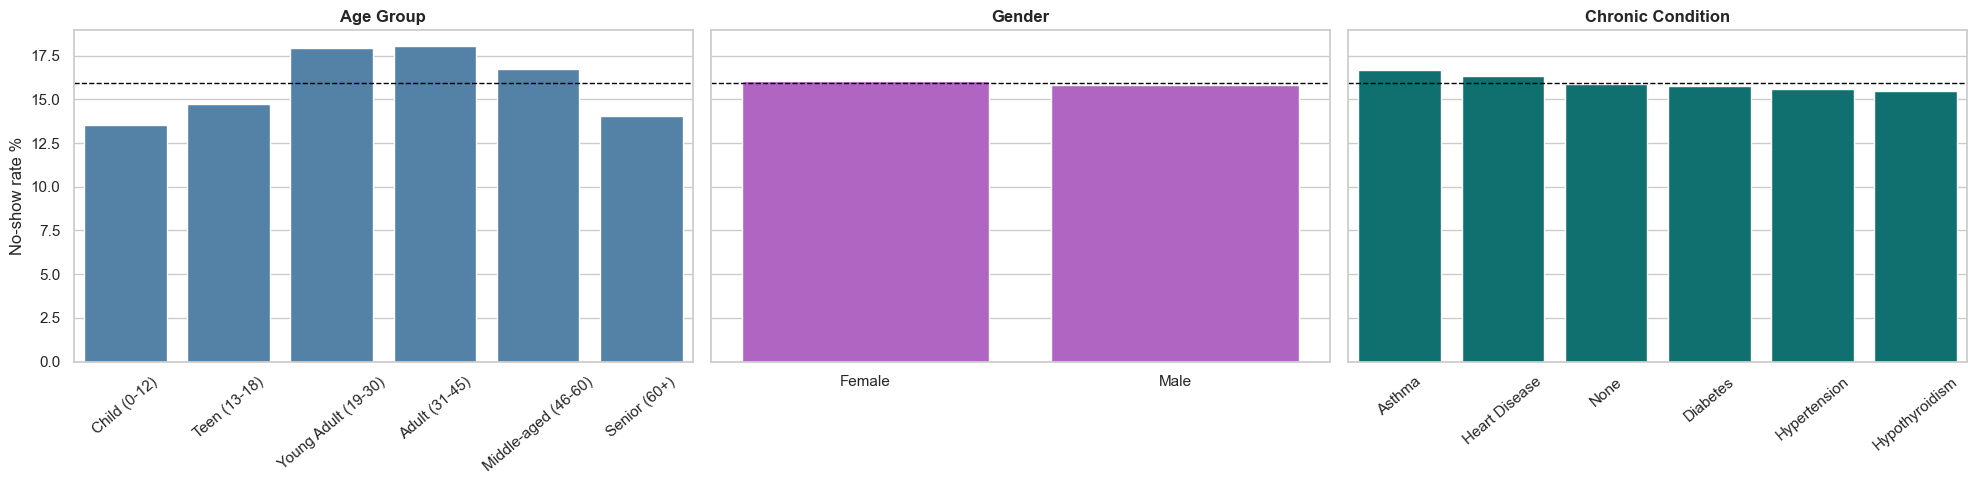

,appointments,no_shows,no_show_rate_%
age_group,,,
Child (0-12),11745,1590,13.54
Teen (13-18),6379,939,14.72
Young Adult (19-30),10017,1797,17.94
Adult (31-45),15133,2731,18.05
Middle-aged (46-60),14862,2491,16.76
Senior (60+),14516,2036,14.03


,appointments,no_shows,no_show_rate_%
patient_gender,,,
Female,37589,6029,16.04
Male,35063,5555,15.84


,appointments,no_shows,no_show_rate_%
patient_chronic_condition,,,
Asthma,9098,1520,16.71
Heart Disease,9155,1494,16.32
None,27144,4314,15.89
Diabetes,9010,1421,15.77
Hypertension,9100,1417,15.57
Hypothyroidism,9145,1418,15.51


,appointments,no_shows,no_show_rate_%
has_chronic,,,
Chronic condition,45508,7270,15.98
No chronic condition,27144,4314,15.89


In [35]:
age_ns = noshow_rate(resolved, "age_group").reindex(age_order)
gen_ns = noshow_rate(resolved, "patient_gender")
chr_ns = noshow_rate(resolved, "patient_chronic_condition").sort_values("no_show_rate_%", ascending=False)
resolved["has_chronic"] = np.where(resolved["patient_chronic_condition"] == "None", "No chronic condition", "Chronic condition")
chr_flag_ns = noshow_rate(resolved, "has_chronic")

fig, ax = plt.subplots(1, 3, figsize=(20, 5), sharey=True)
sns.barplot(x=age_ns.index, y=age_ns["no_show_rate_%"], ax=ax[0], color="steelblue"); ax[0].set_title("Age Group"); ax[0].tick_params(axis="x", rotation=40)
sns.barplot(x=gen_ns.index, y=gen_ns["no_show_rate_%"], ax=ax[1], color="mediumorchid"); ax[1].set_title("Gender")
sns.barplot(x=chr_ns.index, y=chr_ns["no_show_rate_%"], ax=ax[2], color="teal"); ax[2].set_title("Chronic Condition"); ax[2].tick_params(axis="x", rotation=40)
ax[0].set_ylabel("No-show rate %")
for a in ax: a.set_xlabel(""); a.axhline(overall_ns, color="black", ls="--", lw=1)
save_fig("11_demographics_noshow")
display(age_ns); display(gen_ns); display(chr_ns); display(chr_flag_ns)

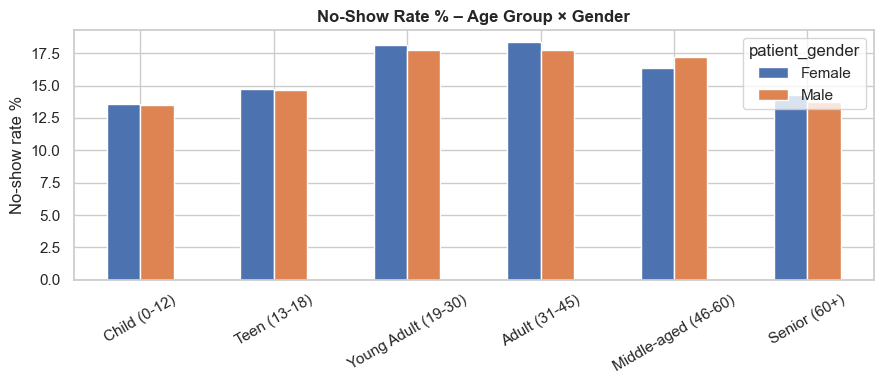

In [36]:
# Age group x Gender
ag = resolved.pivot_table(index="age_group", columns="patient_gender", values="no_show_flag", aggfunc="mean").reindex(age_order) * 100
ag.plot(kind="bar", figsize=(9, 4), title="No-Show Rate % – Age Group × Gender"); plt.ylabel("No-show rate %"); plt.xlabel("")
plt.xticks(rotation=30)
save_fig("11b_age_gender")

,appointments,no_shows,no_show_rate_%,share_of_all_%
visit_reason,,,,
Follow-up,8528,1298,15.22,11.74
Routine Checkup,8377,1309,15.63,11.52
Chronic Condition Management,8117,1266,15.60,11.17
Digestive Problem,7984,1297,16.24,10.99
Fever & Infection,6808,1095,16.08,9.39
Joint Pain,6469,1082,16.73,8.89
Respiratory Issue,6383,1020,15.98,8.79
Injury,5884,949,16.13,8.12
Eye Care,2869,444,15.48,3.95


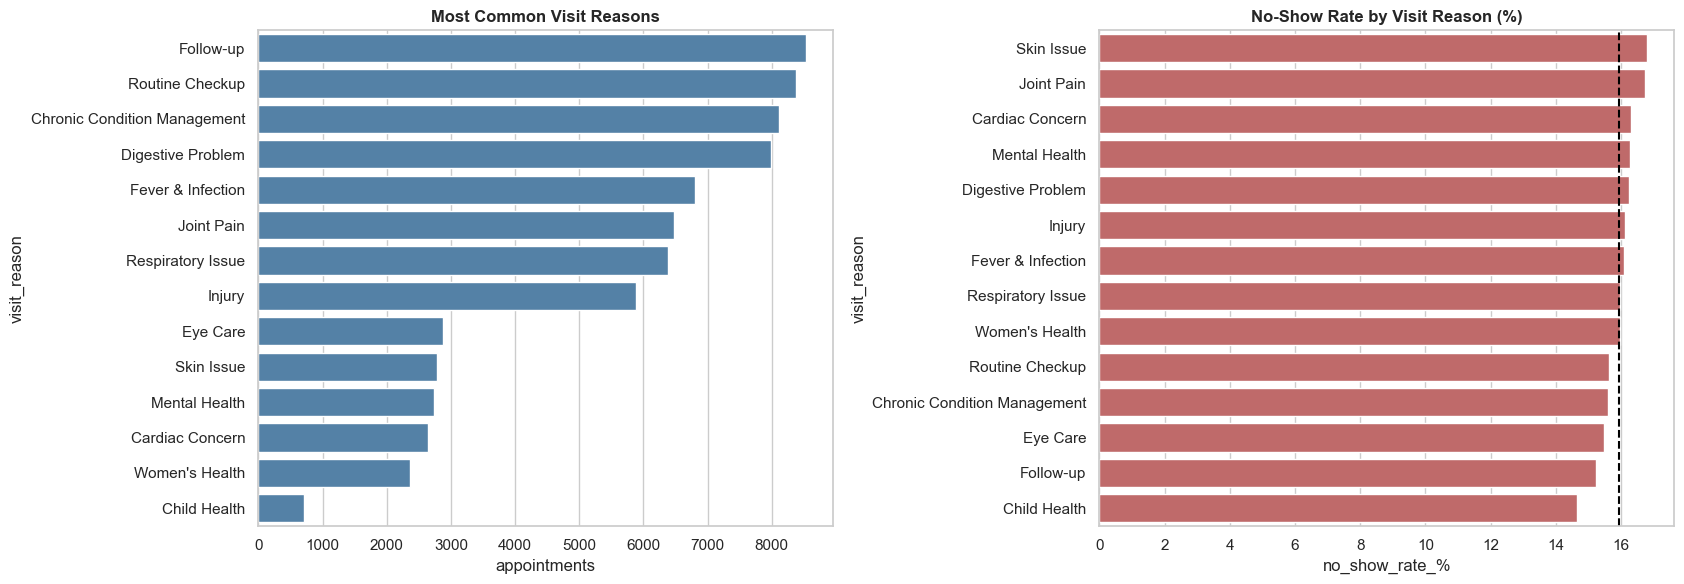

In [37]:
vr = noshow_rate(resolved, "visit_reason")
vr["share_of_all_%"] = fact["visit_reason"].value_counts(normalize=True).mul(100)
vr = vr.sort_values("appointments", ascending=False)
display(vr)

fig, ax = plt.subplots(1, 2, figsize=(17, 6))
sns.barplot(x=vr["appointments"], y=vr.index, ax=ax[0], color="steelblue"); ax[0].set_title("Most Common Visit Reasons")
vr_sorted = vr.sort_values("no_show_rate_%", ascending=False)
sns.barplot(x=vr_sorted["no_show_rate_%"], y=vr_sorted.index, ax=ax[1], color="indianred")
ax[1].axvline(overall_ns, color="black", ls="--"); ax[1].set_title("No-Show Rate by Visit Reason (%)")
save_fig("12_visit_reason")

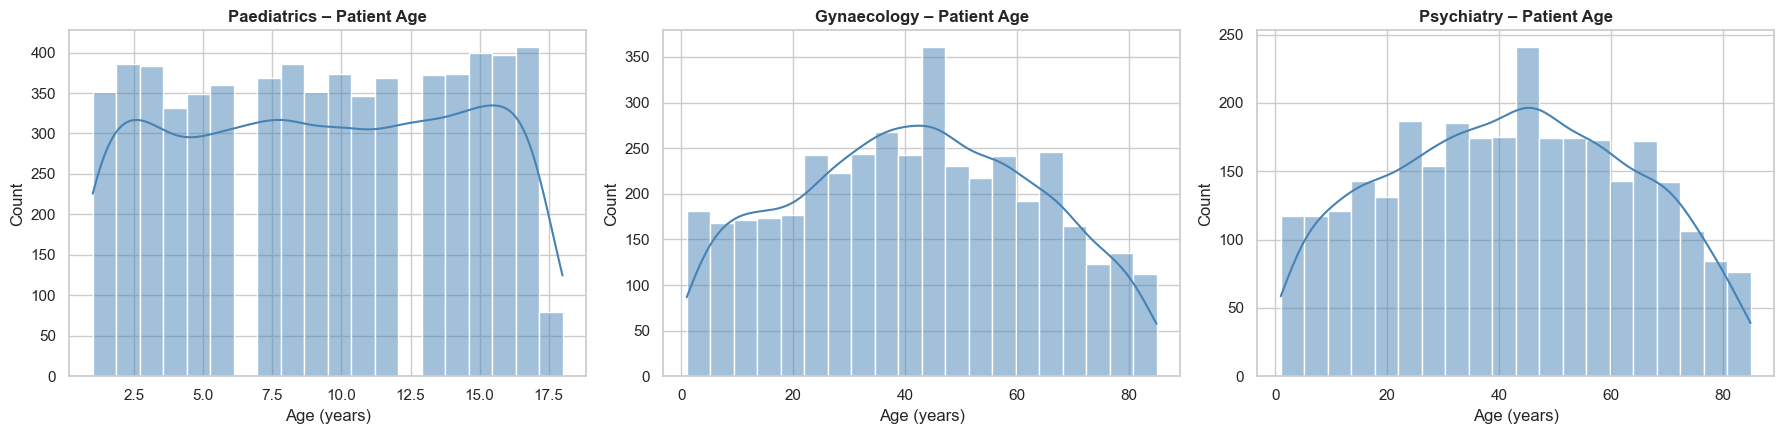

,count,mean,std,min,25%,50%,75%,max
specialty,,,,,,,,
Gynaecology,"4,113.00",41.69,21.74,1.00,25.00,42.00,59.00,85.00
Paediatrics,"6,382.00",9.25,5.01,1.00,5.00,9.00,14.00,18.00
Psychiatry,"2,989.00",41.96,21.72,1.00,25.00,42.00,59.00,85.00


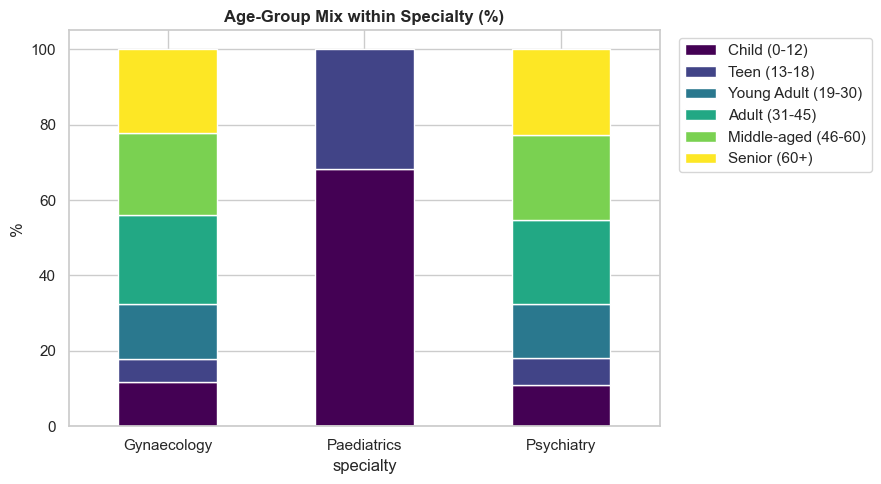

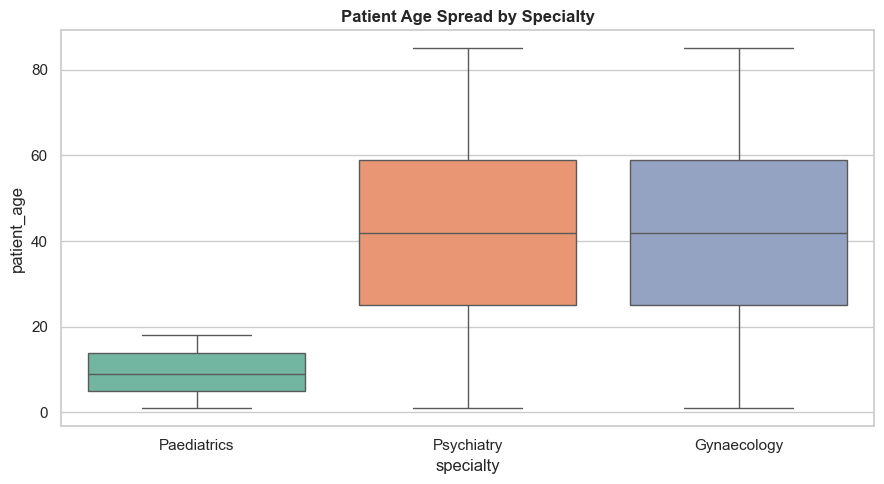

In [38]:
target_specs = ["Paediatrics", "Gynaecology", "Psychiatry"]
sub = fact[fact["specialty"].isin(target_specs)]

fig, ax = plt.subplots(1, 3, figsize=(18, 4.5), sharey=False)
for a, s in zip(ax, target_specs):
    sns.histplot(sub[sub["specialty"] == s]["patient_age"], bins=20, kde=True, ax=a, color="steelblue")
    a.set_title(f"{s} – Patient Age"); a.set_xlabel("Age (years)")
save_fig("13_age_distribution")

display(sub.groupby("specialty")["patient_age"].describe())

ag_mix = pd.crosstab(sub["specialty"], sub["age_group"], normalize="index").reindex(columns=age_order) * 100
ag_mix.plot(kind="bar", stacked=True, figsize=(9, 5), colormap="viridis", title="Age-Group Mix within Specialty (%)")
plt.ylabel("%"); plt.xticks(rotation=0); plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
save_fig("13b_age_group_mix")

plt.figure(figsize=(9, 5)); sns.boxplot(data=sub, x="specialty", y="patient_age", palette="Set2")
plt.title("Patient Age Spread by Specialty")
save_fig("13c_age_boxplot")

In [39]:
# Revenue lost cannot be read directly from the data (no-show rows carry 0 revenue), so we estimate it.
# Method A: listed consultation_fee of every no-show (upper bound, ignores discounts/insurance)
# Method B: average realised revenue per Completed visit in the same specialty x appointment type x applied to each no-show (realistic)
noshow = fact[fact["appointment_status"] == "No-Show"].copy()

avg_rev = completed.groupby(["specialty", "appointment_type"])["revenue_realized"].mean().rename("avg_rev_completed")
noshow = noshow.merge(avg_rev, on=["specialty", "appointment_type"], how="left")

lost_A = noshow["consultation_fee"].sum()
lost_B = noshow["avg_rev_completed"].sum()
realised = completed["revenue_realized"].sum()

print(f"Revenue realised (Completed)                         : ₹{realised:,.0f}")
print(f"Lost to no-shows – Method A (list fee, upper bound)  : ₹{lost_A:,.0f}")
print(f"Lost to no-shows – Method B (avg realised revenue)   : ₹{lost_B:,.0f}")
print(f"Method B as % of realised revenue                    : {lost_B / realised * 100:.1f}%")

Revenue realised (Completed)                         : ₹73,893,798
Lost to no-shows – Method A (list fee, upper bound)  : ₹19,725,460
Lost to no-shows – Method B (avg realised revenue)   : ₹16,213,360
Method B as % of realised revenue                    : 21.9%


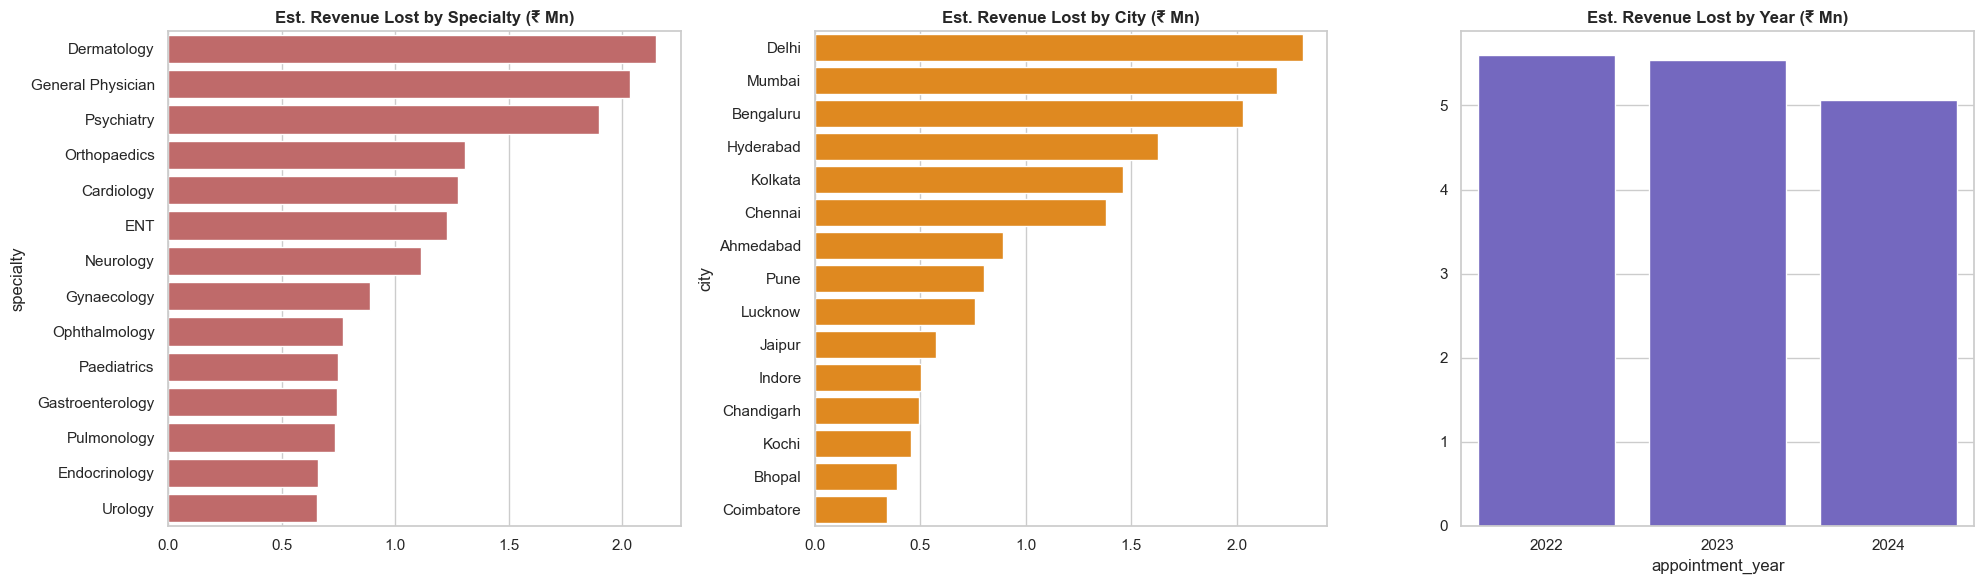

In [40]:
lost_spec = noshow.groupby("specialty")["avg_rev_completed"].sum().sort_values(ascending=False)
lost_city = noshow.groupby("city")["avg_rev_completed"].sum().sort_values(ascending=False)
lost_year = noshow.groupby("appointment_year")["avg_rev_completed"].sum()

fig, ax = plt.subplots(1, 3, figsize=(20, 6))
sns.barplot(x=lost_spec.values / 1e6, y=lost_spec.index, ax=ax[0], color="indianred"); ax[0].set_title("Est. Revenue Lost by Specialty (₹ Mn)")
sns.barplot(x=lost_city.values / 1e6, y=lost_city.index, ax=ax[1], color="darkorange"); ax[1].set_title("Est. Revenue Lost by City (₹ Mn)")
sns.barplot(x=lost_year.index, y=lost_year.values / 1e6, ax=ax[2], color="slateblue"); ax[2].set_title("Est. Revenue Lost by Year (₹ Mn)")
save_fig("14_revenue_lost")

,count,mean,sum
specialty,,,
Psychiatry,1958,"2,640.45",5169997
Neurology,3899,"2,076.48",8096193
Urology,1729,"1,988.62",3438326
Cardiology,3507,"1,940.77",6806264
Gastroenterology,1972,"1,896.82",3740521
Endocrinology,1504,"1,812.68",2726278
Pulmonology,1961,"1,803.23",3536133
Orthopaedics,4189,"1,547.20",6481212
Gynaecology,3134,"1,499.59",4699721


,count,mean,sum
appointment_type,,,
Home Visit,6436,"1,960.05",12614871
In-Clinic,37938,"1,299.83",49312949
Video Consult,10901,"1,097.70",11965978


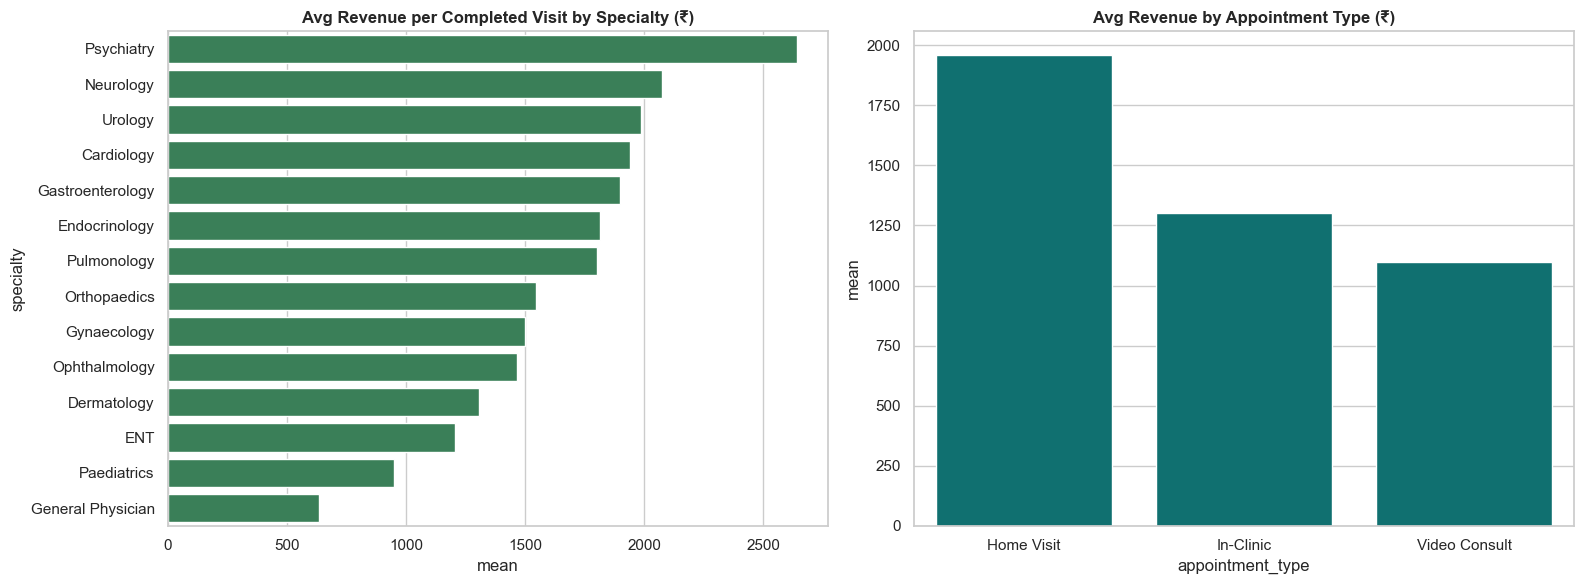

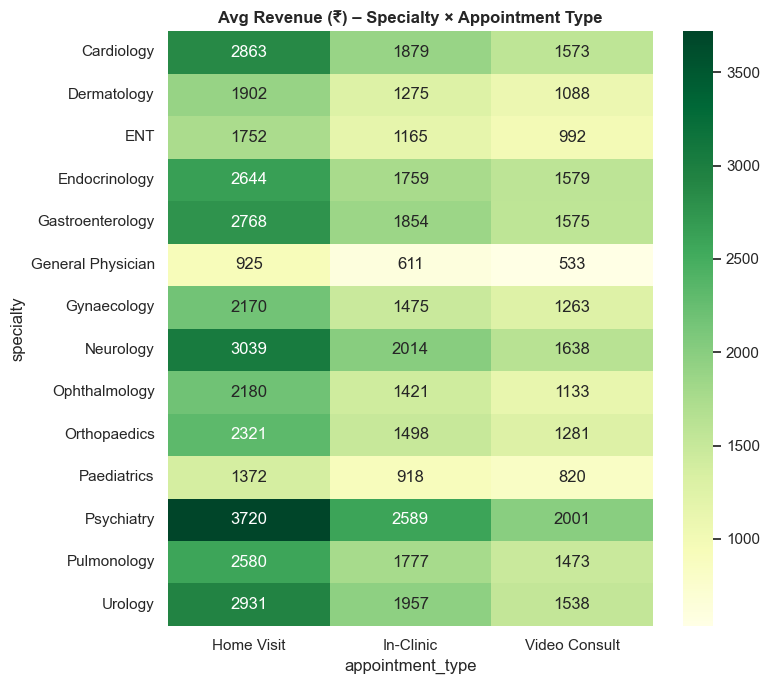

In [41]:
rev_spec = completed.groupby("specialty")["revenue_realized"].agg(["count", "mean", "sum"]).sort_values("mean", ascending=False)
rev_type = completed.groupby("appointment_type")["revenue_realized"].agg(["count", "mean", "sum"]).sort_values("mean", ascending=False)
display(rev_spec); display(rev_type)

fig, ax = plt.subplots(1, 2, figsize=(16, 6))
sns.barplot(x=rev_spec["mean"], y=rev_spec.index, ax=ax[0], color="seagreen"); ax[0].set_title("Avg Revenue per Completed Visit by Specialty (₹)")
sns.barplot(x=rev_type.index, y=rev_type["mean"], ax=ax[1], color="teal"); ax[1].set_title("Avg Revenue by Appointment Type (₹)")
save_fig("15_avg_revenue")

hm = completed.pivot_table(index="specialty", columns="appointment_type", values="revenue_realized", aggfunc="mean")
plt.figure(figsize=(8, 7)); sns.heatmap(hm, annot=True, fmt=".0f", cmap="YlGn")
plt.title("Avg Revenue (₹) – Specialty × Appointment Type")
save_fig("15b_revenue_heatmap")

,total_revenue,share_pct
city,,
Bengaluru,9990616,13.52
Delhi,9958247,13.48
Mumbai,8989613,12.17
Hyderabad,7503245,10.15
Chennai,7188473,9.73
Kolkata,6543084,8.85
Pune,4734139,6.41
Ahmedabad,3956890,5.35
Lucknow,3177444,4.30


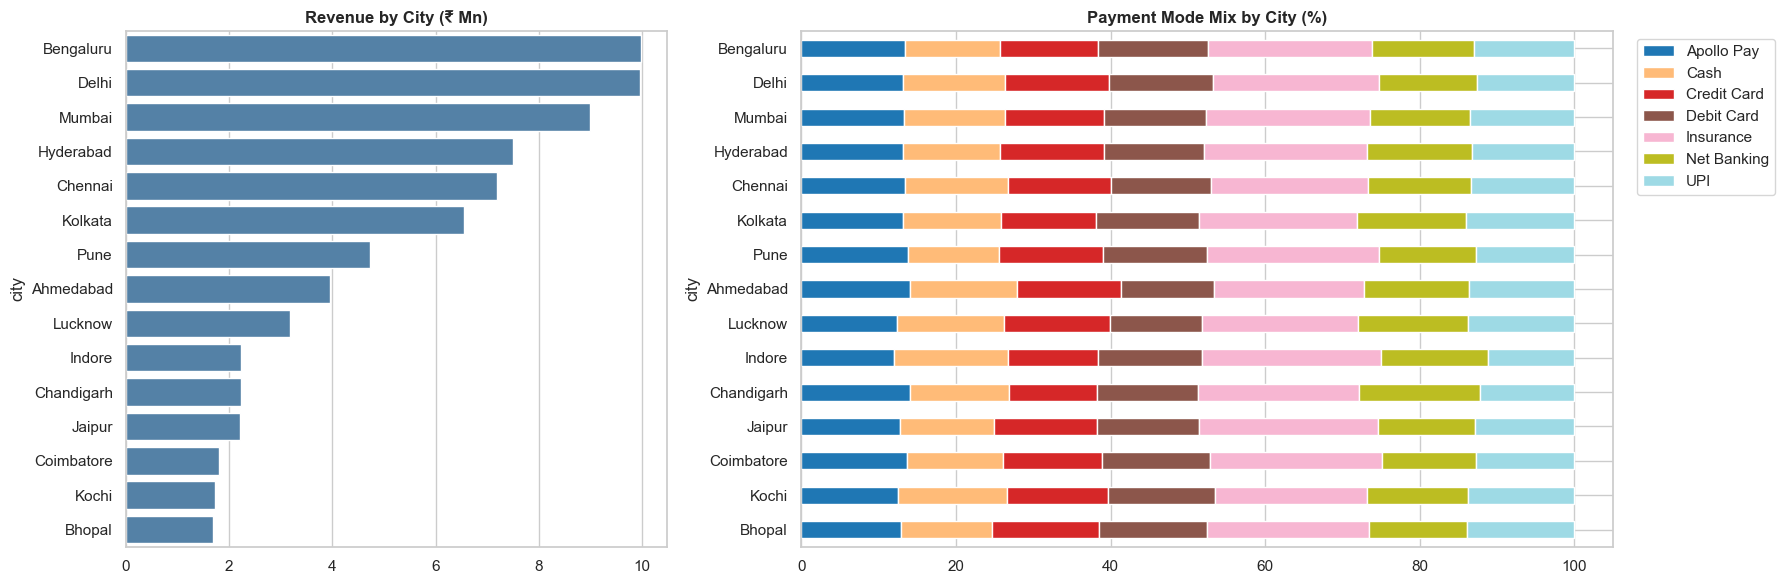

Overall payment-mode mix (%):


,share_%
payment_mode,
Insurance,21.06
Debit Card,13.30
Net Banking,13.30
Apollo Pay,13.25
UPI,13.13
Credit Card,13.05
Cash,12.91


In [42]:
city_rev = completed.groupby("city")["revenue_realized"].sum().sort_values(ascending=False)
display(city_rev.to_frame("total_revenue").assign(share_pct=lambda d: d["total_revenue"] / d["total_revenue"].sum() * 100))

pay = pd.crosstab(completed["city"], completed["payment_mode"], normalize="index").loc[city_rev.index] * 100

fig, ax = plt.subplots(1, 2, figsize=(18, 6), gridspec_kw={"width_ratios": [1, 1.5]})
sns.barplot(x=city_rev.values / 1e6, y=city_rev.index, ax=ax[0], color="steelblue"); ax[0].set_title("Revenue by City (₹ Mn)")
pay.plot(kind="barh", stacked=True, ax=ax[1], colormap="tab20"); ax[1].set_title("Payment Mode Mix by City (%)")
ax[1].legend(bbox_to_anchor=(1.02, 1), loc="upper left"); ax[1].invert_yaxis()
save_fig("16_city_revenue_payment")

overall_pay = completed["payment_mode"].value_counts(normalize=True) * 100
print("Overall payment-mode mix (%):"); display(overall_pay.to_frame("share_%"))

,visits,avg_fee_charged,avg_insurer_pays,avg_out_of_pocket,avg_apollo_revenue,oop_share_of_fee_%
insurance_coverage,,,,,,
No,37523,"1,562.82",0.00,"1,562.82","1,562.82",100.00
Yes,17752,"1,556.35",697.17,859.18,859.18,55.20


,visits,avg_insurer_pays,avg_out_of_pocket
insurance_provider,,,
Bajaj Allianz,3606,694.01,856.92
HDFC ERGO,3497,717.31,855.67
New India Assurance,3598,680.96,870.84
Niva Bupa,3541,701.46,843.61
Star Health,3510,692.65,868.72


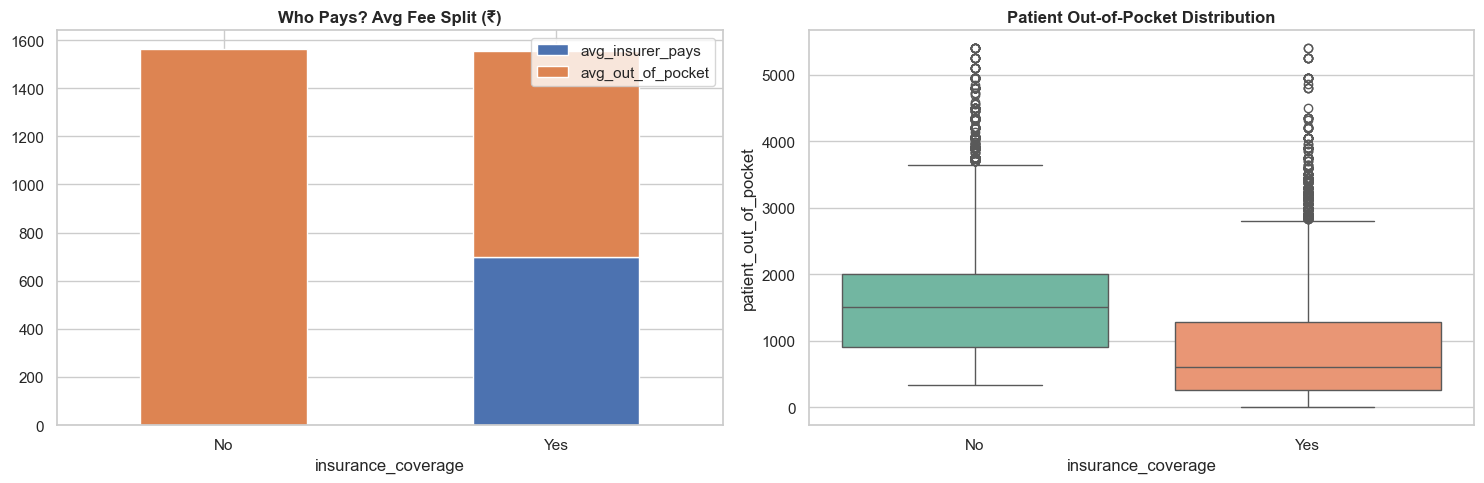

In [43]:
ins = completed.groupby("insurance_coverage").agg(
    visits=("appointment_id", "count"),
    avg_fee_charged=("actual_fee_charged", "mean"),
    avg_insurer_pays=("insurance_covered_amount", "mean"),
    avg_out_of_pocket=("patient_out_of_pocket", "mean"),
    avg_apollo_revenue=("revenue_realized", "mean"),
)
ins["oop_share_of_fee_%"] = ins["avg_out_of_pocket"] / ins["avg_fee_charged"] * 100
display(ins)

ins_prov = completed[completed["insurance_coverage"] == "Yes"].groupby("insurance_provider").agg(
    visits=("appointment_id", "count"),
    avg_insurer_pays=("insurance_covered_amount", "mean"),
    avg_out_of_pocket=("patient_out_of_pocket", "mean"))
display(ins_prov)

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
ins[["avg_insurer_pays", "avg_out_of_pocket"]].plot(kind="bar", stacked=True, ax=ax[0], color=["#4c72b0", "#dd8452"])
ax[0].set_title("Who Pays? Avg Fee Split (₹)"); ax[0].tick_params(axis="x", rotation=0)
sns.boxplot(data=completed, x="insurance_coverage", y="patient_out_of_pocket", ax=ax[1], palette="Set2")
ax[1].set_title("Patient Out-of-Pocket Distribution")
save_fig("17_insurance_oop")

In [44]:
# Does insurance also change the discount received / realised revenue?
print(completed.groupby("insurance_coverage")[["discount_pct", "actual_fee_charged", "revenue_realized"]].mean())

                    discount_pct  actual_fee_charged  revenue_realized
insurance_coverage                                                    
No                          3.87            1,562.82          1,562.82
Yes                         4.12            1,556.35            859.18


,mean,median,count
specialty,,,
Gastroenterology,77.26,77.75,1972
Endocrinology,77.15,77.70,1504
Cardiology,76.81,76.90,3507
Gynaecology,76.80,77.10,3134
Paediatrics,76.66,76.50,4900
Neurology,76.63,76.60,3899
General Physician,76.59,76.40,14981
Urology,76.44,77.00,1729
Orthopaedics,76.43,76.50,4189


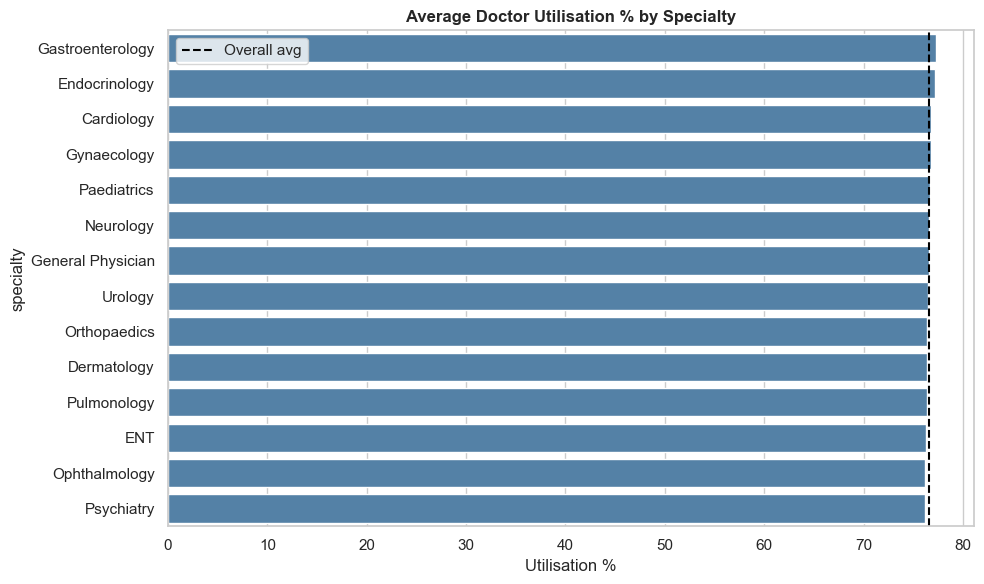

Highest: Gastroenterology (77.3%) | Lowest: Psychiatry (76.2%)


In [45]:
util = completed.groupby("specialty")["doctor_utilization_pct"].agg(["mean", "median", "count"]).sort_values("mean", ascending=False)
display(util)

plt.figure(figsize=(10, 6))
sns.barplot(x=util["mean"], y=util.index, color="steelblue")
plt.axvline(completed["doctor_utilization_pct"].mean(), color="black", ls="--", label="Overall avg"); plt.legend()
plt.title("Average Doctor Utilisation % by Specialty"); plt.xlabel("Utilisation %")
save_fig("18_utilisation_specialty")
print(f"Highest: {util.index[0]} ({util['mean'].iloc[0]:.1f}%) | Lowest: {util.index[-1]} ({util['mean'].iloc[-1]:.1f}%)")

count   55,275.00
mean        11.55
std         12.05
min          0.00
25%          3.00
50%          8.00
75%         16.00
max         90.00
Name: wait_time_minutes, dtype: float64


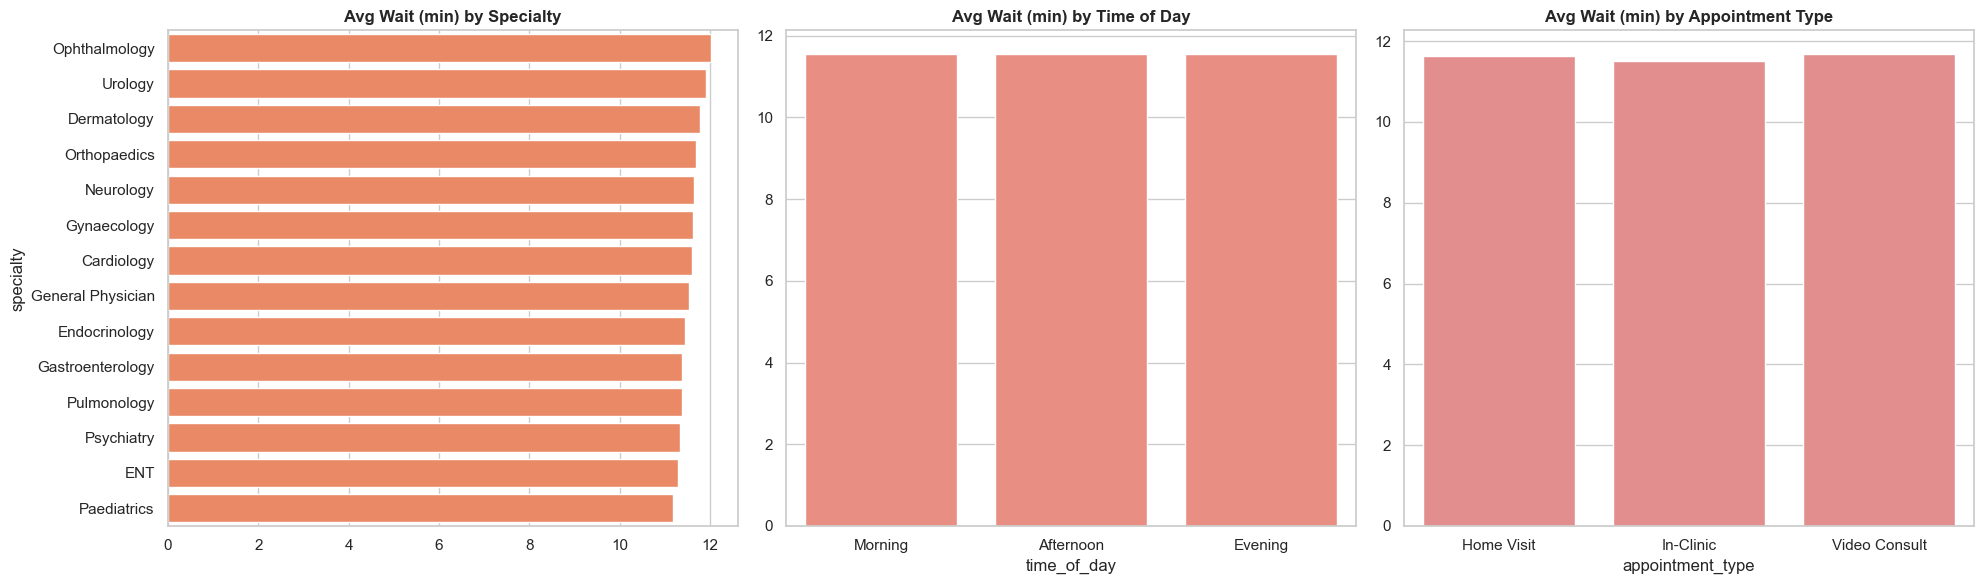

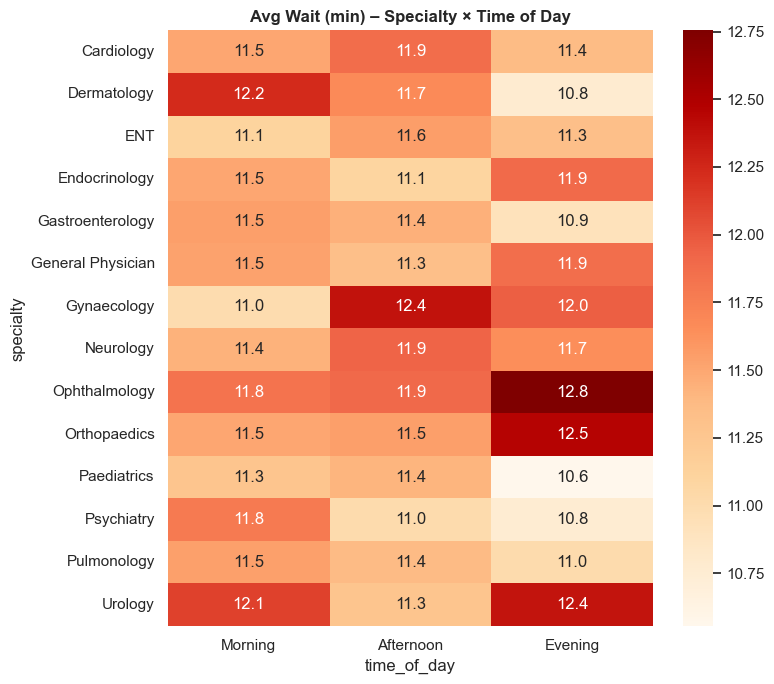

In [46]:
print(completed["wait_time_minutes"].describe())

wait_spec = completed.groupby("specialty")["wait_time_minutes"].mean().sort_values(ascending=False)
wait_tod = completed.groupby("time_of_day")["wait_time_minutes"].mean().reindex(["Morning", "Afternoon", "Evening"])
wait_type = completed.groupby("appointment_type")["wait_time_minutes"].mean()

fig, ax = plt.subplots(1, 3, figsize=(20, 6))
sns.barplot(x=wait_spec.values, y=wait_spec.index, ax=ax[0], color="coral"); ax[0].set_title("Avg Wait (min) by Specialty")
sns.barplot(x=wait_tod.index, y=wait_tod.values, ax=ax[1], color="salmon"); ax[1].set_title("Avg Wait (min) by Time of Day")
sns.barplot(x=wait_type.index, y=wait_type.values, ax=ax[2], color="lightcoral"); ax[2].set_title("Avg Wait (min) by Appointment Type")
save_fig("19_wait_time")

hm = completed.pivot_table(index="specialty", columns="time_of_day", values="wait_time_minutes", aggfunc="mean")[["Morning", "Afternoon", "Evening"]]
plt.figure(figsize=(8, 7)); sns.heatmap(hm, annot=True, fmt=".1f", cmap="OrRd"); plt.title("Avg Wait (min) – Specialty × Time of Day")
save_fig("19b_wait_heatmap")

,consultation_duration_min,patient_satisfaction_score,wait_time_minutes
consultation_duration_min,1.00,-0.00,0.00
patient_satisfaction_score,-0.00,1.00,0.01
wait_time_minutes,0.00,0.01,1.00


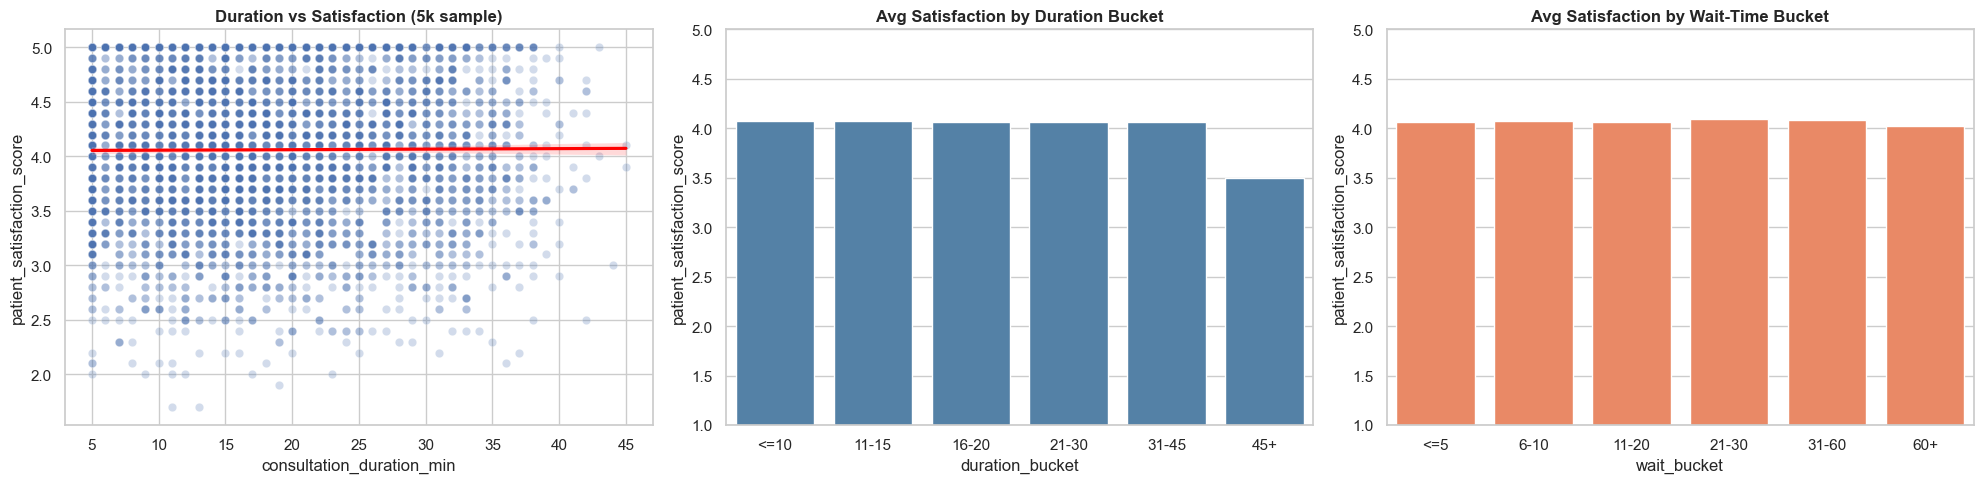

In [47]:
corr = completed[["consultation_duration_min", "patient_satisfaction_score", "wait_time_minutes"]].corr()
display(corr)

fig, ax = plt.subplots(1, 3, figsize=(20, 5))
sample = completed.sample(5000, random_state=42)
sns.scatterplot(data=sample, x="consultation_duration_min", y="patient_satisfaction_score", alpha=0.25, ax=ax[0])
sns.regplot(data=sample, x="consultation_duration_min", y="patient_satisfaction_score", scatter=False, color="red", ax=ax[0])
ax[0].set_title("Duration vs Satisfaction (5k sample)")

completed["duration_bucket"] = pd.cut(completed["consultation_duration_min"], bins=[0, 10, 15, 20, 30, 45, 200], labels=["<=10", "11-15", "16-20", "21-30", "31-45", "45+"])
sns.barplot(data=completed, x="duration_bucket", y="patient_satisfaction_score", ax=ax[1], color="steelblue", errorbar=None)
ax[1].set_title("Avg Satisfaction by Duration Bucket"); ax[1].set_ylim(1, 5)

completed["wait_bucket"] = pd.cut(completed["wait_time_minutes"], bins=[-1, 5, 10, 20, 30, 60, 300], labels=["<=5", "6-10", "11-20", "21-30", "31-60", "60+"])
sns.barplot(data=completed, x="wait_bucket", y="patient_satisfaction_score", ax=ax[2], color="coral", errorbar=None)
ax[2].set_title("Avg Satisfaction by Wait-Time Bucket"); ax[2].set_ylim(1, 5)
save_fig("20_duration_satisfaction")

Correlation experience vs LISTED fee           : 0.278
Correlation experience vs AVG ACTUAL fee charged: 0.279


,count,mean,median
exp_band,,,
0-5,51,"1,319.61","1,400.00"
6-10,60,"1,445.00","1,500.00"
11-15,46,"1,515.22","1,500.00"
16-20,60,"1,530.00","1,550.00"
21+,103,"1,850.49","1,800.00"


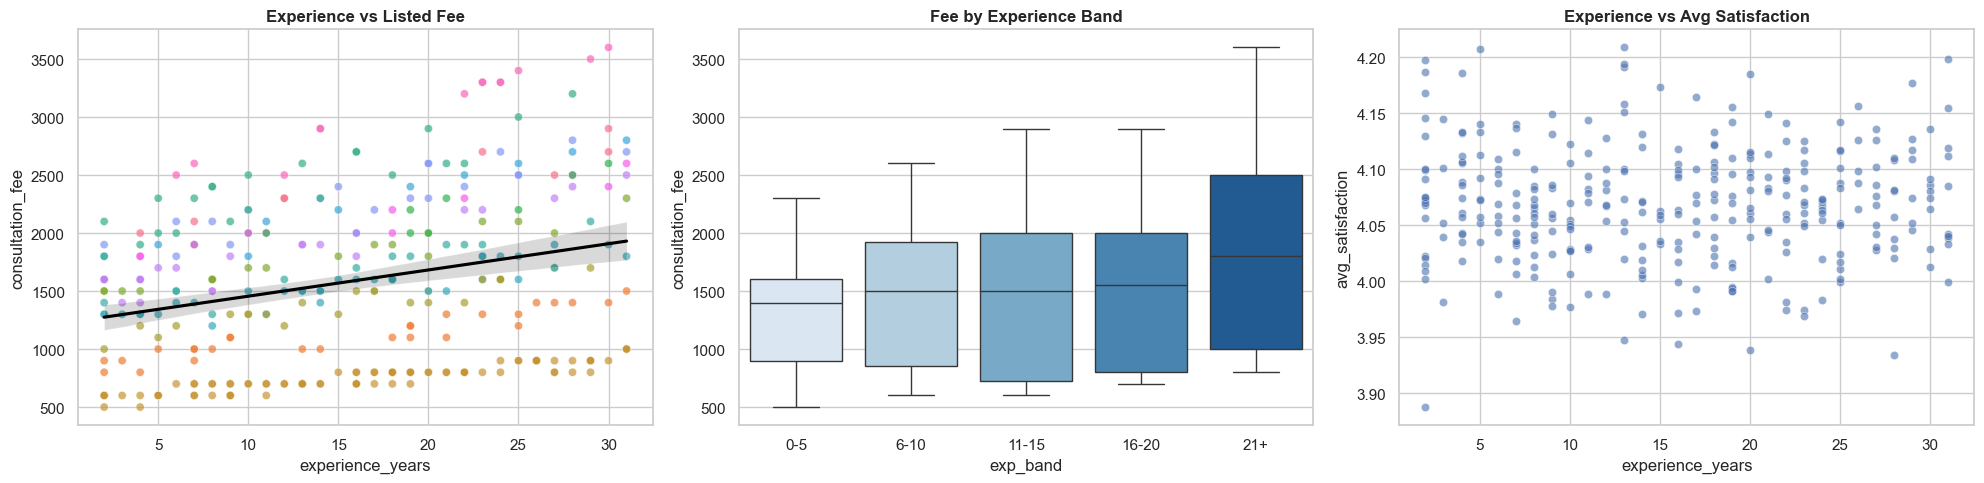

In [48]:
# Doctor-level table: join fact (completed) aggregates with doctors dimension
doc_perf = (completed.groupby("doctor_id")
            .agg(visits=("appointment_id", "count"),
                 avg_fee_charged=("actual_fee_charged", "mean"),
                 avg_satisfaction=("patient_satisfaction_score", "mean"))
            .reset_index()
            .merge(doctors, on="doctor_id", how="left"))

print("Correlation experience vs LISTED fee           :", round(doctors["experience_years"].corr(doctors["consultation_fee"]), 3))
print("Correlation experience vs AVG ACTUAL fee charged:", round(doc_perf["experience_years"].corr(doc_perf["avg_fee_charged"]), 3))

doctors["exp_band"] = pd.cut(doctors["experience_years"], bins=[0, 5, 10, 15, 20, 35], labels=["0-5", "6-10", "11-15", "16-20", "21+"])
display(doctors.groupby("exp_band", observed=True)["consultation_fee"].agg(["count", "mean", "median"]))

fig, ax = plt.subplots(1, 3, figsize=(20, 5))
sns.scatterplot(data=doctors, x="experience_years", y="consultation_fee", hue="specialty", ax=ax[0], legend=False, alpha=0.7)
sns.regplot(data=doctors, x="experience_years", y="consultation_fee", scatter=False, color="black", ax=ax[0]); ax[0].set_title("Experience vs Listed Fee")
sns.boxplot(data=doctors, x="exp_band", y="consultation_fee", ax=ax[1], palette="Blues"); ax[1].set_title("Fee by Experience Band")
sns.scatterplot(data=doc_perf, x="experience_years", y="avg_satisfaction", ax=ax[2], alpha=0.6); ax[2].set_title("Experience vs Avg Satisfaction")
save_fig("21_experience_fee")

In [49]:
# Specialty is a confounder (e.g. Cardiology fees are higher than GP fees) – check the relationship inside specialties
within = doctors.groupby("specialty").apply(lambda g: g["experience_years"].corr(g["consultation_fee"])).sort_values(ascending=False)
print("Within-specialty correlation (experience vs fee):"); display(within.to_frame("corr"))

Within-specialty correlation (experience vs fee):


,corr
specialty,
Psychiatry,0.98
Gynaecology,0.97
Pulmonology,0.97
Gastroenterology,0.95
Orthopaedics,0.95
Paediatrics,0.93
ENT,0.93
Ophthalmology,0.93
Urology,0.93
